# Hyperparameters in Deep Learning — a hands-on tour with PyTorch Lightning

This notebook builds a small but complete image-classification framework on **Fashion-MNIST** and uses it to study **hyperparameters**: what they are, where they live in the code, and what happens when you change them.

**What you will build**

1. One `HParams` config object that holds *every* hyperparameter in one place
2. A `LightningDataModule` (data), a CNN (`nn.Module`) and a `LightningModule` (training logic)
3. A `fit()` helper that trains a model from a config and returns its learning curves
4. Controlled experiments: learning rate, batch size, optimizer, regularisation
5. A small random search, then one final evaluation on the test set

**Parameters vs. hyperparameters**

| | Parameters | Hyperparameters |
|---|---|---|
| What | Weights and biases of the network | Settings that define the model and how it is trained |
| Who sets them | The optimizer, by gradient descent | You, before training starts |
| Learned from | Training data | Validation performance (trial and comparison) |
| Examples | Conv kernels, linear weights | Learning rate, batch size, dropout, number of layers |

A useful mental model: the optimizer searches for good **parameters** inside a search problem that the **hyperparameters** define. Bad hyperparameters make that inner problem hard or impossible, no matter how long you train.

## 0. Setup

Uncomment the next cell if the packages are not installed yet (for example on a fresh Colab runtime).

In [1]:
# %pip install torch torchvision lightning pandas matplotlib

In [2]:
import logging
import random
import time
import warnings
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Lightning 2.x is imported as `lightning`; older installs use `pytorch_lightning`.
try:
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    _LIGHTNING_LOGGER = "lightning.pytorch"
except ImportError:
    import pytorch_lightning as L
    from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
    from pytorch_lightning.loggers import CSVLogger
    _LIGHTNING_LOGGER = "pytorch_lightning"

# Keep the output readable during the many short training runs below.
warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*logging interval.*")

print("torch:", torch.__version__)
print("lightning:", L.__version__)
print("GPU available:", torch.cuda.is_available())

torch: 2.15.0+cu132
lightning: 2.6.6
GPU available: False


## 1. All hyperparameters in one place

The single most useful habit when working with hyperparameters is to **keep them out of the code body**. Nothing below this cell contains a hard-coded `0.001` or `64`; every tunable number is a field of `HParams`.

This gives you three things for free:

- **Reproducibility** — a run is fully described by one small object
- **Easy experiments** — `replace(hp, lr=0.01)` creates a variant without touching the model
- **Logging** — Lightning stores the config next to the metrics and inside every checkpoint

The fields fall into four families:

| Family | Fields | What they control |
|---|---|---|
| **Data** | `batch_size`, `val_fraction`, `train_subset`, `augment` | What the model sees in each step |
| **Model (architecture)** | `conv1_channels`, `conv2_channels`, `hidden_dim`, `activation`, `use_batchnorm`, `dropout` | Capacity: how complex a function the network can represent |
| **Optimisation** | `optimizer`, `lr`, `momentum`, `weight_decay`, `scheduler` | How the weights move at each step |
| **Training loop** | `max_epochs`, `patience`, `seed` | How long training runs and where it starts from |

In [3]:
@dataclass
class HParams:
    # ---- Data -------------------------------------------------------------
    data_dir: str = "./data"
    batch_size: int = 64          # samples per gradient step
    val_fraction: float = 0.1     # share of the training set held out for validation
    train_subset: Optional[int] = None  # use only N training images (None = all); for fast experiments
    augment: bool = False         # random crop + horizontal flip on training images
    num_workers: int = 0          # data-loading processes (not a model hyperparameter; 0 is safest in notebooks)

    # ---- Model ------------------------------------------------------------
    conv1_channels: int = 32      # width of the first conv block
    conv2_channels: int = 64      # width of the second conv block
    hidden_dim: int = 128         # size of the fully connected layer
    activation: str = "relu"      # relu | leaky_relu | gelu | tanh
    use_batchnorm: bool = True    # batch normalisation after each conv
    dropout: float = 0.25         # probability of zeroing an activation in the classifier head

    # ---- Optimisation -----------------------------------------------------
    optimizer: str = "adam"       # sgd | adam | adamw
    lr: float = 1e-3              # learning rate (step size)
    momentum: float = 0.9         # used by SGD only
    weight_decay: float = 0.0     # L2-style penalty on the weights
    scheduler: str = "none"       # none | step | cosine

    # ---- Training loop ----------------------------------------------------
    max_epochs: int = 5           # upper limit on passes over the training set
    patience: int = 3             # early stopping: epochs without val_loss improvement before stopping
    seed: int = 42                # controls weight init, data split and shuffling


hp = HParams()
pd.Series(asdict(hp), name="value").to_frame()

,value
data_dir,./data
batch_size,64
val_fraction,0.1
train_subset,None
augment,False
num_workers,0
conv1_channels,32
conv2_channels,64
hidden_dim,128
activation,relu


## 2. Data: Fashion-MNIST in a `LightningDataModule`

Fashion-MNIST ships with `torchvision.datasets`: 60,000 training and 10,000 test images, 28×28 grayscale, 10 clothing classes. It is as small as MNIST but hard enough that hyperparameter choices visibly matter.

**Three splits, three jobs**

- **Train** — used to fit the *parameters*
- **Validation** — used to choose the *hyperparameters* (and for early stopping)
- **Test** — used **once**, at the very end, to report the final number

If you tune hyperparameters on the test set, the test score stops being an honest estimate of how the model performs on new data. That is why `val_fraction` exists.

**Hyperparameters used here**

- `batch_size` — how many images make up one gradient estimate
- `val_fraction` — bigger means a more reliable validation score but less training data
- `augment` — random transformations that make the training set effectively larger (a form of regularisation)
- `train_subset` — not something you would tune for a final model, but very handy for cheap experiments

In [4]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Mean and standard deviation of the Fashion-MNIST training pixels.
FMNIST_MEAN, FMNIST_STD = (0.2860,), (0.3530,)


class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        normalize = transforms.Normalize(FMNIST_MEAN, FMNIST_STD)
        self.eval_transform = transforms.Compose([transforms.ToTensor(), normalize])

        augmentations = []
        if hp.augment:  # <-- hyperparameter: augment
            augmentations = [transforms.RandomCrop(28, padding=2),
                             transforms.RandomHorizontalFlip()]
        self.train_transform = transforms.Compose([*augmentations, transforms.ToTensor(), normalize])

    def prepare_data(self):
        # Download once. Lightning calls this on a single process.
        datasets.FashionMNIST(self.hp.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        # Two views of the same 60k images: one with training transforms, one without.
        train_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.train_transform)
        eval_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.eval_transform)

        n_total = len(train_view)
        n_val = int(n_total * self.hp.val_fraction)  # <-- hyperparameter: val_fraction
        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(n_total, generator=generator).tolist()
        val_idx, train_idx = indices[:n_val], indices[n_val:]

        if self.hp.train_subset is not None:  # <-- hyperparameter: train_subset
            train_idx = train_idx[: self.hp.train_subset]

        self.train_ds = Subset(train_view, train_idx)
        self.val_ds = Subset(eval_view, val_idx)
        self.test_ds = datasets.FashionMNIST(self.hp.data_dir, train=False, transform=self.eval_transform)

    def _loader(self, dataset, batch_size, shuffle):
        return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                          num_workers=self.hp.num_workers,
                          persistent_workers=self.hp.num_workers > 0)

    def train_dataloader(self):
        return self._loader(self.train_ds, self.hp.batch_size, shuffle=True)  # <-- hyperparameter: batch_size

    def val_dataloader(self):
        # The evaluation batch size only affects speed, never the result.
        return self._loader(self.val_ds, 512, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_ds, 512, shuffle=False)

train: 54,000   val: 6,000   test: 10,000
batch shape: (512, 1, 28, 28)


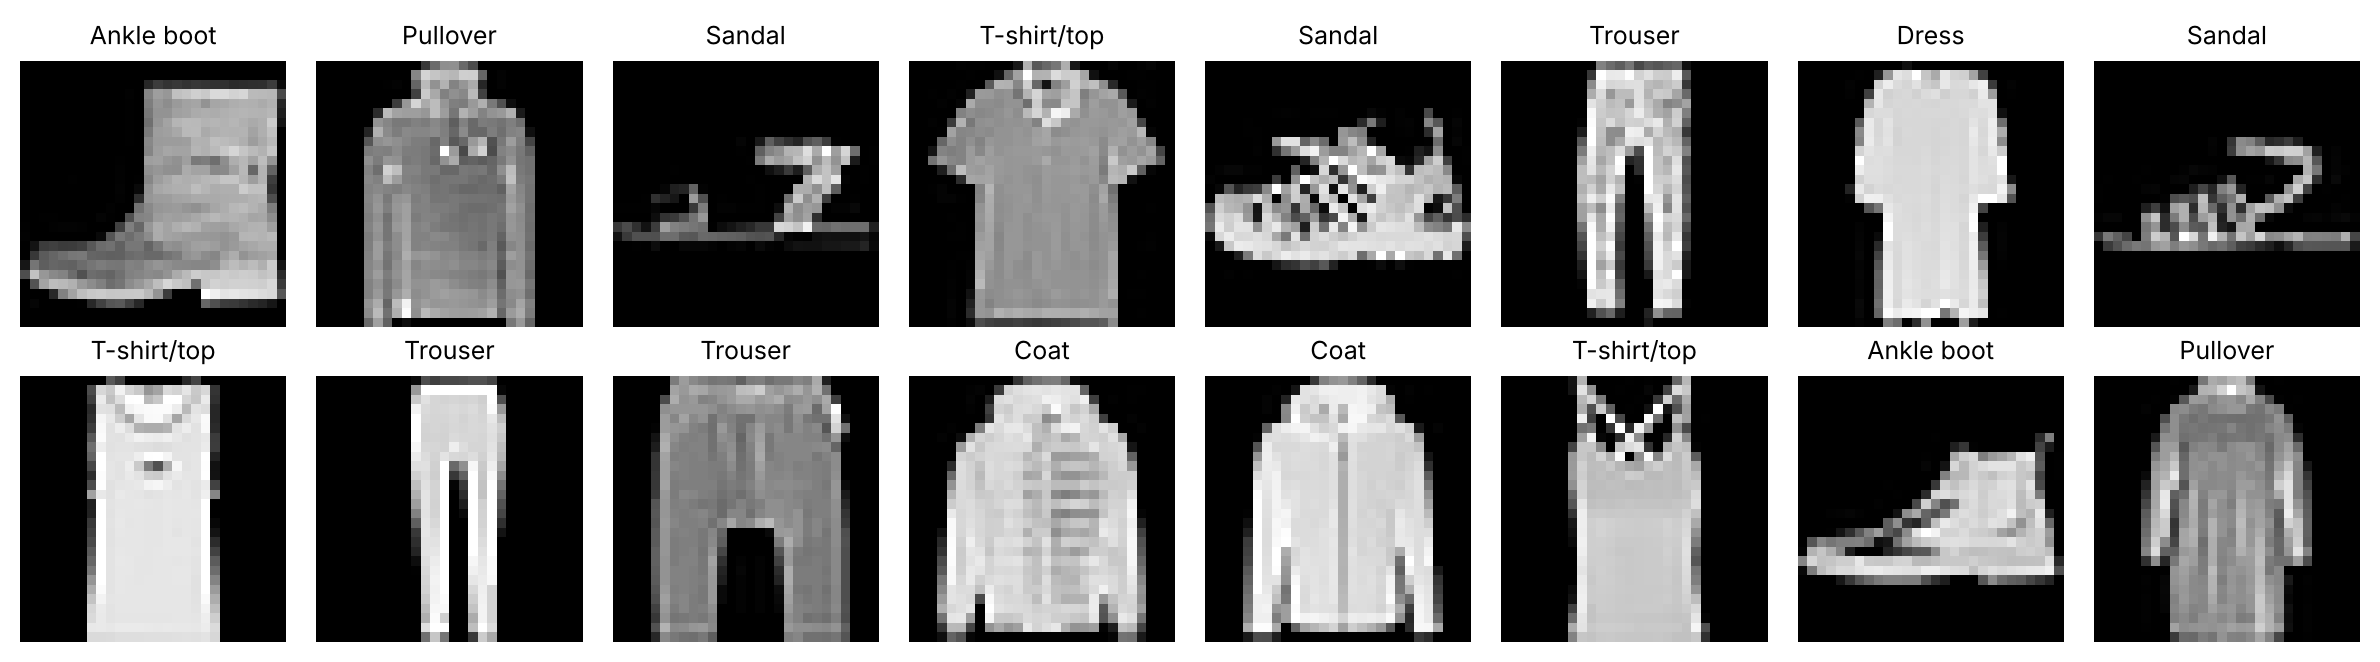

In [5]:
dm = FashionMNISTDataModule(hp)
dm.prepare_data()
dm.setup()
print(f"train: {len(dm.train_ds):,}   val: {len(dm.val_ds):,}   test: {len(dm.test_ds):,}")

images, labels = next(iter(dm.val_dataloader()))
print("batch shape:", tuple(images.shape))

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, label in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze() * FMNIST_STD[0] + FMNIST_MEAN[0], cmap="gray")
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Model: architecture hyperparameters

The network is a classic small CNN:

```
input 1×28×28
 → Conv(3×3, conv1_channels) → [BatchNorm] → activation → MaxPool   (14×14)
 → Conv(3×3, conv2_channels) → [BatchNorm] → activation → MaxPool   (7×7)
 → Flatten → Dropout → Linear(hidden_dim) → activation → Dropout → Linear(10)
```

Every architectural choice is read from `HParams`:

- **Width** (`conv1_channels`, `conv2_channels`, `hidden_dim`) sets the **capacity** of the model. More capacity can fit more complex patterns, but costs compute and overfits more easily.
- **`activation`** is the non-linearity. ReLU is the default workhorse; GELU and LeakyReLU are common alternatives; tanh saturates and usually trains more slowly in deep networks.
- **`use_batchnorm`** normalises activations within each batch. It tends to make training faster and much less sensitive to the learning rate.
- **`dropout`** randomly zeroes activations during training, which discourages the network from relying on any single feature. It is a regulariser: it lowers training accuracy on purpose in exchange for better generalisation.

Depth (the number of layers) is also a hyperparameter. It is fixed at two conv blocks here to keep the notebook short; see the exercises at the end.

In [6]:
ACTIVATIONS = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU, "tanh": nn.Tanh}


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act = ACTIVATIONS[hp.activation]            # <-- hyperparameter: activation
        c1, c2 = hp.conv1_channels, hp.conv2_channels  # <-- hyperparameters: width

        def conv_block(in_ch, out_ch):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
            if hp.use_batchnorm:                    # <-- hyperparameter: use_batchnorm
                layers.append(nn.BatchNorm2d(out_ch))
            layers += [act(), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(conv_block(1, c1), conv_block(c1, c2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),                 # <-- hyperparameter: dropout
            nn.Linear(c2 * 7 * 7, hp.hidden_dim),   # <-- hyperparameter: hidden_dim
            act(),
            nn.Dropout(hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


model = SmallCNN(hp)
print(model)
print(f"\ntrainable parameters: {count_parameters(model):,}")

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

trainable parameters: 421,834


Architecture hyperparameters change the **number of parameters**, and you can see that without training anything:

In [7]:
variants = {
    "tiny   (8, 16, 32)": dict(conv1_channels=8, conv2_channels=16, hidden_dim=32),
    "small  (16, 32, 64)": dict(conv1_channels=16, conv2_channels=32, hidden_dim=64),
    "default (32, 64, 128)": dict(),
    "wide   (64, 128, 256)": dict(conv1_channels=64, conv2_channels=128, hidden_dim=256),
}
pd.DataFrame(
    {"trainable parameters": {name: count_parameters(SmallCNN(replace(hp, **overrides)))
                              for name, overrides in variants.items()}}
)

,trainable parameters
"tiny (8, 16, 32)",26746
"small (16, 32, 64)",105962
"default (32, 64, 128)",421834
"wide (64, 128, 256)",1683338


## 4. Training logic: the `LightningModule`

A `LightningModule` wraps the network and answers three questions:

1. **What is one training step?** → `training_step`
2. **How do we evaluate?** → `validation_step`, `test_step`
3. **How do the weights get updated?** → `configure_optimizers`

`configure_optimizers` is where the **optimisation hyperparameters** live.

### Learning rate

Plain gradient descent updates the weights $\theta$ with

$$\theta \leftarrow \theta - \eta \,\nabla_\theta \mathcal{L}(\theta)$$

where $\eta$ is the **learning rate**. It is usually the most important hyperparameter:

- **too small** → training crawls and may stop far from a good solution within your epoch budget
- **too large** → the loss oscillates or blows up
- **about right** → the loss drops quickly and settles

### Optimizer

- **SGD** uses the raw gradient. With **`momentum`** it keeps a running average of past gradients, which smooths the path and speeds things up along consistent directions.
- **Adam** adapts the step size per parameter. It usually works well out of the box with `lr ≈ 1e-3`.
- **AdamW** is Adam with weight decay applied correctly (decoupled from the adaptive step). Prefer it over Adam whenever `weight_decay > 0`.

Good learning rates are **not transferable between optimizers**: `0.1` can be fine for SGD and disastrous for Adam.

### Weight decay

Shrinks the weights a little at every step, which is equivalent in spirit to adding $\lambda \lVert\theta\rVert^2$ to the loss. It pushes the model towards simpler solutions (regularisation).

### Learning-rate scheduler

Changes $\eta$ during training. A common pattern is to start with larger steps to make fast progress and finish with smaller steps to settle. `step` divides the rate by 10 at fixed intervals; `cosine` lowers it smoothly to zero.

The call to `save_hyperparameters` stores the config in `self.hparams`, in the logger output (`hparams.yaml`) and inside every checkpoint.

In [8]:
class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))  # logged + stored in checkpoints
        self.model = SmallCNN(hp)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch, stage: str):
        x, y = batch
        logits = self(x)
        loss = self.loss_fn(logits, y)
        acc = (logits.argmax(dim=1) == y).float().mean()
        # on_epoch=True: Lightning averages over the epoch (weighted by batch size).
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log(f"{stage}_acc", acc, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._shared_step(batch, "test")

    def configure_optimizers(self):
        hp = self.hp
        params = self.parameters()

        # <-- hyperparameters: optimizer, lr, momentum, weight_decay
        if hp.optimizer == "sgd":
            optimizer = torch.optim.SGD(params, lr=hp.lr, momentum=hp.momentum, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adam":
            optimizer = torch.optim.Adam(params, lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adamw":
            optimizer = torch.optim.AdamW(params, lr=hp.lr, weight_decay=hp.weight_decay)
        else:
            raise ValueError(f"unknown optimizer: {hp.optimizer}")

        # <-- hyperparameter: scheduler
        if hp.scheduler == "none":
            return optimizer
        if hp.scheduler == "step":
            scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, hp.max_epochs // 3), gamma=0.1)
        elif hp.scheduler == "cosine":
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=hp.max_epochs)
        else:
            raise ValueError(f"unknown scheduler: {hp.scheduler}")
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}

## 5. The training loop: `Trainer` hyperparameters

Lightning's `Trainer` replaces the hand-written loop (`for epoch ... for batch ... loss.backward() ...`). The hyperparameters that belong to the loop itself are:

- **`max_epochs`** — one epoch is one full pass over the training set. Too few and the model **underfits**; too many and it may **overfit** (and you waste compute).
- **`patience`** (early stopping) — stop when `val_loss` has not improved for this many epochs. This turns "how many epochs?" from a guess into something the validation set decides. `max_epochs` then acts as an upper limit.
- **`seed`** — fixes the random weight initialisation, the data split and the shuffling order. Two runs with different seeds give slightly different results, so small differences between hyperparameter settings may just be noise.

The `fit()` helper below is the whole "framework": config in, trained model and learning curves out. Everything after this section is just calling it with different configs.

In [9]:
def load_history(log_dir) -> pd.DataFrame:
    """Read Lightning's metrics.csv and return one row per epoch."""
    df = pd.read_csv(Path(log_dir) / "metrics.csv")
    cols = [c for c in ["train_loss", "val_loss", "train_acc", "val_acc"] if c in df.columns]
    return df.groupby("epoch")[cols].mean().reset_index()


def fit(hp: HParams, run_name: str = "run", verbose: bool = True, checkpoint: bool = False):
    """Train one model from a config. Returns (trainer, model, datamodule, history)."""
    for name in (_LIGHTNING_LOGGER, "lightning.fabric", "lightning_fabric"):
        logging.getLogger(name).setLevel(logging.INFO if verbose else logging.ERROR)
    L.seed_everything(hp.seed, workers=True)  # <-- hyperparameter: seed

    datamodule = FashionMNISTDataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger("logs", name=run_name)

    callbacks = [EarlyStopping(monitor="val_loss", mode="min", patience=hp.patience)]  # <-- hyperparameter: patience
    if checkpoint:
        callbacks.append(ModelCheckpoint(monitor="val_acc", mode="max", save_top_k=1))

    trainer = L.Trainer(
        max_epochs=hp.max_epochs,          # <-- hyperparameter: max_epochs
        accelerator="auto",                # GPU if there is one, otherwise CPU
        devices=1,
        logger=logger,
        callbacks=callbacks,
        enable_checkpointing=checkpoint,
        enable_progress_bar=verbose,
        enable_model_summary=verbose,
        log_every_n_steps=10,
    )
    trainer.fit(model, datamodule=datamodule)
    history = load_history(logger.log_dir)
    return trainer, model, datamodule, history

### Baseline run

Start with the defaults. A baseline matters: every later experiment is only meaningful as "better or worse than the baseline".

In [10]:
baseline_hp = HParams()
trainer, model, dm, baseline_history = fit(baseline_hp, run_name="baseline")
baseline_history

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name    | Type             | Params | Mode  | FLOPs
-------------------------------------------------------------
0 | model   | SmallCNN         | 421 K  | train | 0    
1 | loss_fn | CrossEntropyLoss | 0      | train | 0    
-------------------------------------------------------------
421 K     Trainable params
0         Non-trainable params
421 K     Total params
1.687     Total estimated model params size (MB)
20        Modules in train mode
0         Modules in eval mode
0         Total Flops
/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and t

Epoch 4: 100%|██████████| 844/844 [00:43<00:00, 19.55it/s, v_num=0, val_loss=0.237, val_acc=0.915, train_loss=0.227, train_acc=0.917]


`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|██████████| 844/844 [00:43<00:00, 19.55it/s, v_num=0, val_loss=0.237, val_acc=0.915, train_loss=0.227, train_acc=0.917]


,epoch,train_loss,val_loss,train_acc,val_acc
0,0,0.439852,0.292298,0.841630,0.891500
1,1,0.305882,0.267623,0.888093,0.898833
2,2,0.272793,0.249227,0.899630,0.909500
3,3,0.248859,0.239090,0.908074,0.914833
4,4,0.227308,0.237112,0.917130,0.915167


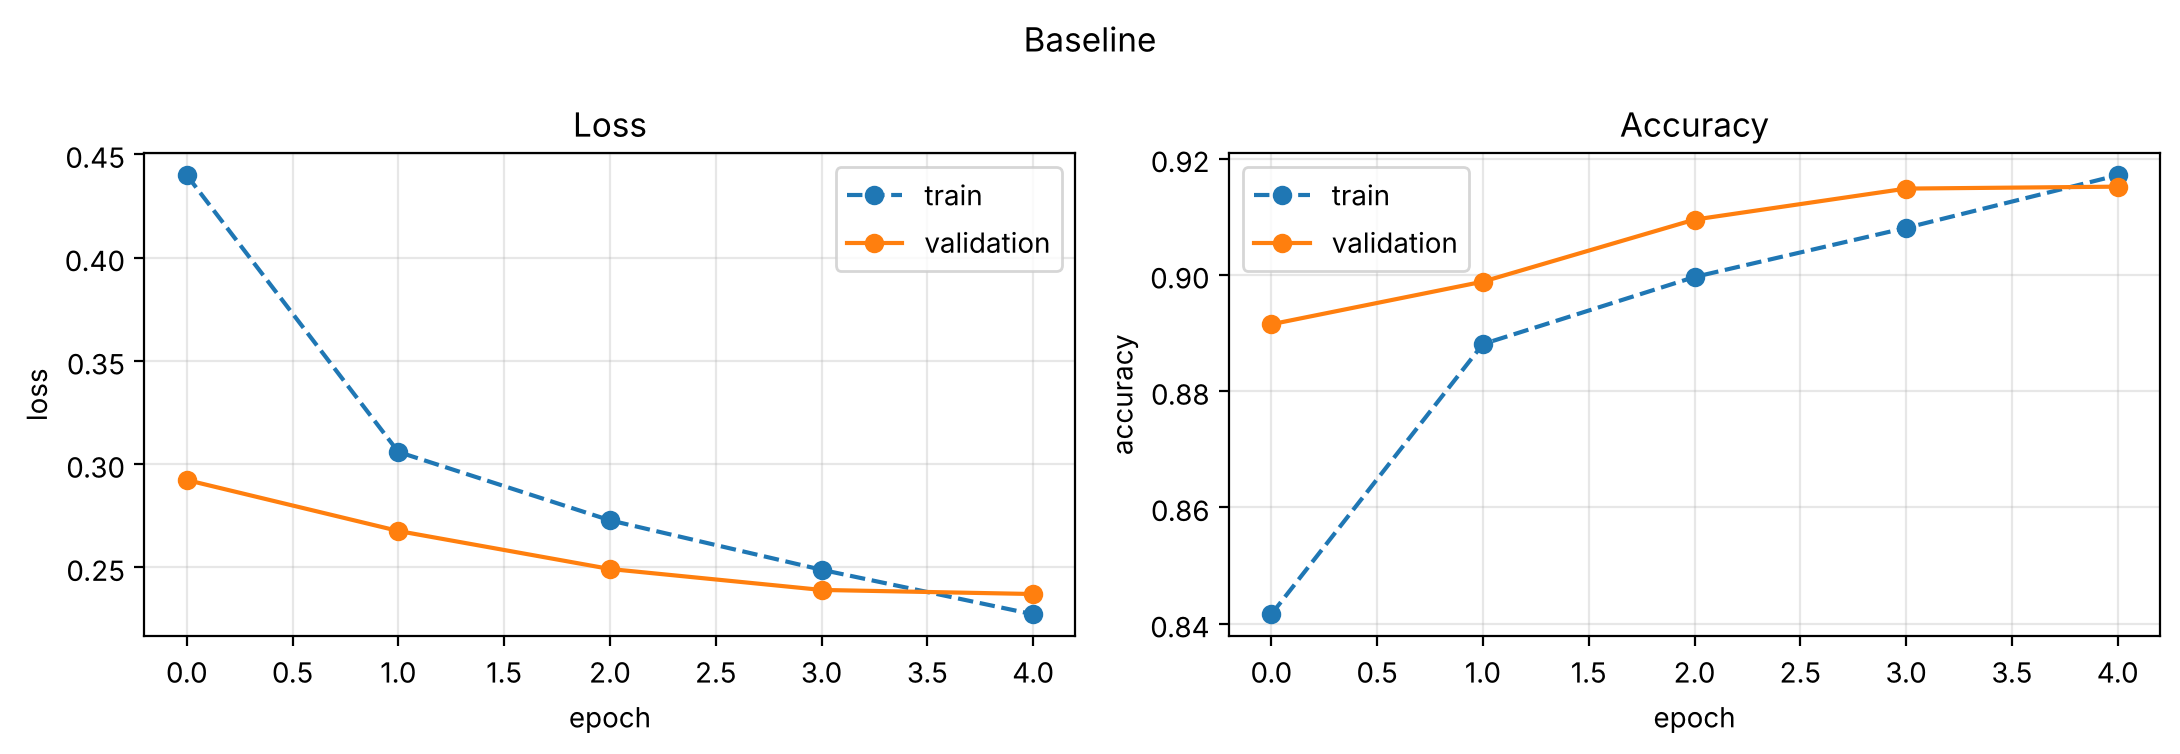

In [11]:
def plot_history(history: pd.DataFrame, title: str = ""):
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.8))
    ax_loss.plot(history["epoch"], history["train_loss"], "o--", label="train")
    ax_loss.plot(history["epoch"], history["val_loss"], "o-", label="validation")
    ax_loss.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax_acc.plot(history["epoch"], history["train_acc"], "o--", label="train")
    ax_acc.plot(history["epoch"], history["val_acc"], "o-", label="validation")
    ax_acc.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
    for ax in (ax_loss, ax_acc):
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(baseline_history, "Baseline")

**How to read learning curves**

| What you see | Diagnosis | Hyperparameters to try |
|---|---|---|
| Train and validation loss both high and still falling | Underfitting / not trained long enough | More epochs, higher `lr`, bigger model |
| Train loss low, validation loss rising | Overfitting | More `dropout`, `weight_decay`, `augment`, smaller model, early stopping |
| Loss jumps around or becomes `nan` | Step size too large | Lower `lr`, add batch norm |
| Loss barely moves from the start | Step size too small (or far too large) | Raise `lr` by 10× and look again |

One detail in this notebook: the training metrics are averaged *during* the epoch, with dropout switched on, while validation runs *after* the epoch with dropout off. So training accuracy can sit a little **below** validation accuracy early on. That is expected, not a bug.

## 6. Experiments: change one thing at a time

To see the effect of one hyperparameter, hold everything else fixed and vary only that one. To keep each run to seconds rather than minutes, the experiments use a **fast config**: 10,000 training images and 4 epochs, with early stopping effectively switched off so every run has the same length.

This is a **proxy**: cheap, and good for seeing *trends*. The best value on a small proxy is not guaranteed to be the best value on the full dataset.

`run_configs` trains one model per entry and collects the learning curves.

In [12]:
FAST = replace(HParams(), train_subset=10_000, max_epochs=4, patience=100)


def run_configs(experiment: str, configs: dict, base: HParams = FAST) -> dict:
    """Train one model per entry of `configs` ({label: {field: value}})."""
    results = {}
    for i, (label, overrides) in enumerate(configs.items()):
        hp_i = replace(base, **overrides)
        start = time.perf_counter()
        _, _, _, history = fit(hp_i, run_name=f"{experiment}/run_{i}", verbose=False)
        seconds = time.perf_counter() - start
        results[label] = {"hp": hp_i, "history": history, "seconds": seconds}
        print(f"{label:<28} best val_acc = {history['val_acc'].max():.4f}   ({seconds:.0f}s)")
    return results


def summarize(results: dict) -> pd.DataFrame:
    rows = []
    for label, r in results.items():
        h = r["history"]
        rows.append({
            "run": label,
            "best_val_acc": h["val_acc"].max(),
            "final_val_loss": h["val_loss"].iloc[-1],
            "final_train_loss": h["train_loss"].iloc[-1],
            "epochs": len(h),
            "seconds": round(r["seconds"], 1),
        })
    return pd.DataFrame(rows).set_index("run")


def plot_runs(results: dict, title: str = "", metrics=("val_loss", "val_acc")):
    fig, axes = plt.subplots(1, len(metrics), figsize=(5.5 * len(metrics), 3.8))
    for ax, metric in zip(axes, metrics):
        for label, r in results.items():
            ax.plot(r["history"]["epoch"], r["history"][metric], "o-", label=label)
        ax.set(xlabel="epoch", ylabel=metric, title=metric)
        ax.grid(alpha=0.3)
    axes[-1].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### 6.1 Learning rate

Learning rates are searched on a **logarithmic scale**: the difference between `0.001` and `0.01` matters far more than the difference between `0.051` and `0.060`. So try powers of ten first, then refine around the best one.

**What to look for:** the smallest rate learns slowly and is still improving when training ends; the largest is unstable or stuck near chance (10% accuracy, loss ≈ 2.3); the best one sits in between.

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=1e-05                     best val_acc = 0.7745   (38s)
lr=0.0001                    best val_acc = 0.8552   (36s)
lr=0.001                     best val_acc = 0.8725   (37s)
lr=0.01                      best val_acc = 0.8505   (36s)
lr=0.1                       best val_acc = 0.6878   (32s)


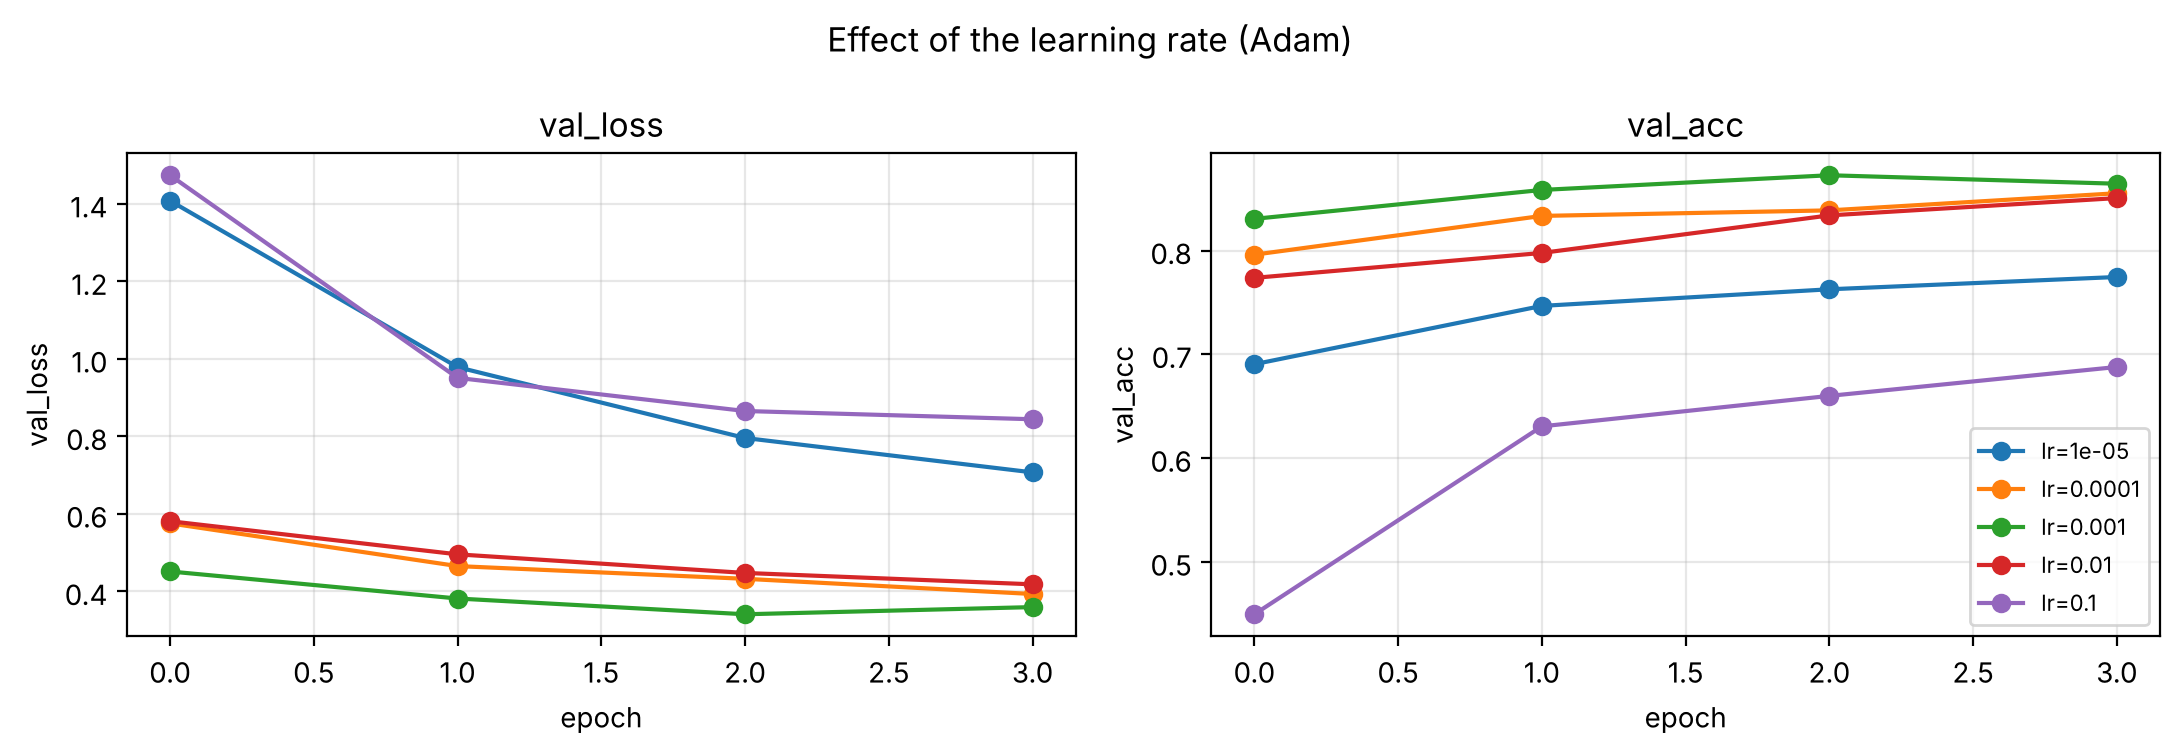

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
lr=1e-05,0.774500,0.707266,0.827023,4,37.6
lr=0.0001,0.855167,0.393514,0.417038,4,35.7
lr=0.001,0.872500,0.359716,0.316017,4,37.2
lr=0.01,0.850500,0.418487,0.518073,4,35.9
lr=0.1,0.687833,0.844341,1.192647,4,32.3


In [13]:
lr_values = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
lr_results = run_configs("lr", {f"lr={v:g}": {"lr": v} for v in lr_values})
plot_runs(lr_results, "Effect of the learning rate (Adam)")
summarize(lr_results)

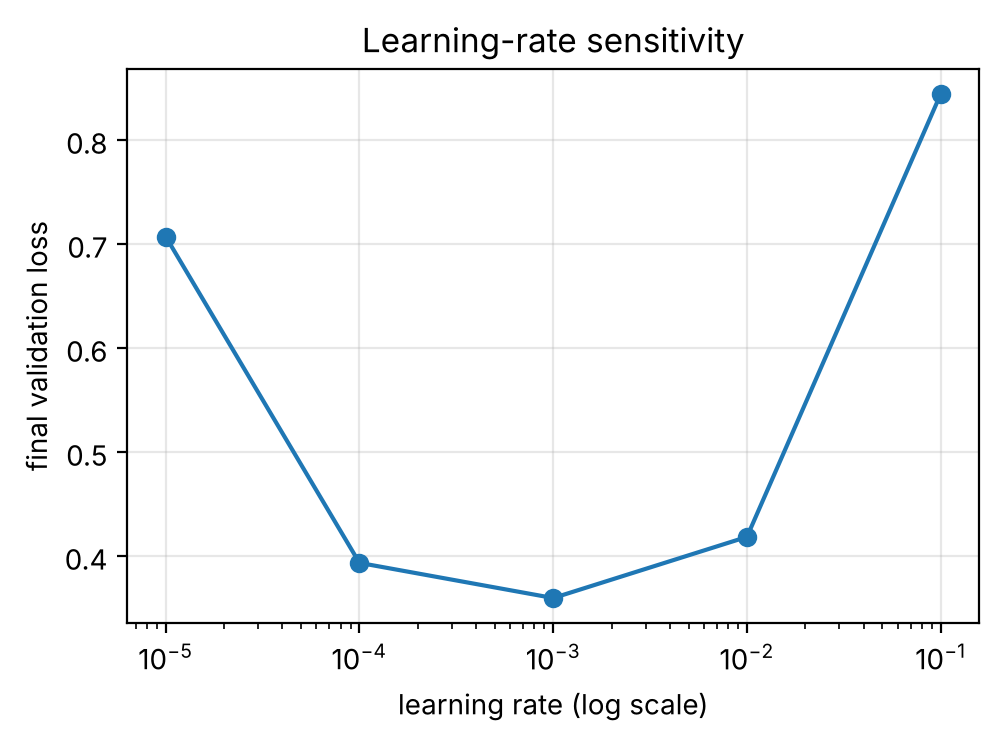

In [14]:
# The classic "U-shape" view: final validation loss against learning rate on a log axis.
final_losses = [lr_results[f"lr={v:g}"]["history"]["val_loss"].iloc[-1] for v in lr_values]
plt.figure(figsize=(5.5, 3.6))
plt.semilogx(lr_values, final_losses, "o-")
plt.xlabel("learning rate (log scale)")
plt.ylabel("final validation loss")
plt.title("Learning-rate sensitivity")
plt.grid(alpha=0.3)
plt.show()

### 6.2 Batch size

The batch size sets how many images are averaged into each gradient estimate.

- **Small batches** → noisy gradients, many updates per epoch, slower per epoch. The noise can act as a mild regulariser.
- **Large batches** → smooth gradients, few updates per epoch, faster per epoch on a GPU, more memory.

The important catch: with a fixed number of epochs, a larger batch means **fewer weight updates**. With 10,000 images, batch 16 gives 625 updates per epoch and batch 512 gives only 20. So batch size and learning rate are **coupled**: when you increase the batch size, you usually need to increase the learning rate too (a common rule of thumb is to scale them together).

**What to look for:** compare both accuracy and the `seconds` column. The experiment keeps `lr` fixed on purpose so you can see the coupling.

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


batch_size=16                best val_acc = 0.8705   (49s)
batch_size=64                best val_acc = 0.8725   (35s)
batch_size=256               best val_acc = 0.8660   (34s)
batch_size=1024              best val_acc = 0.8430   (39s)


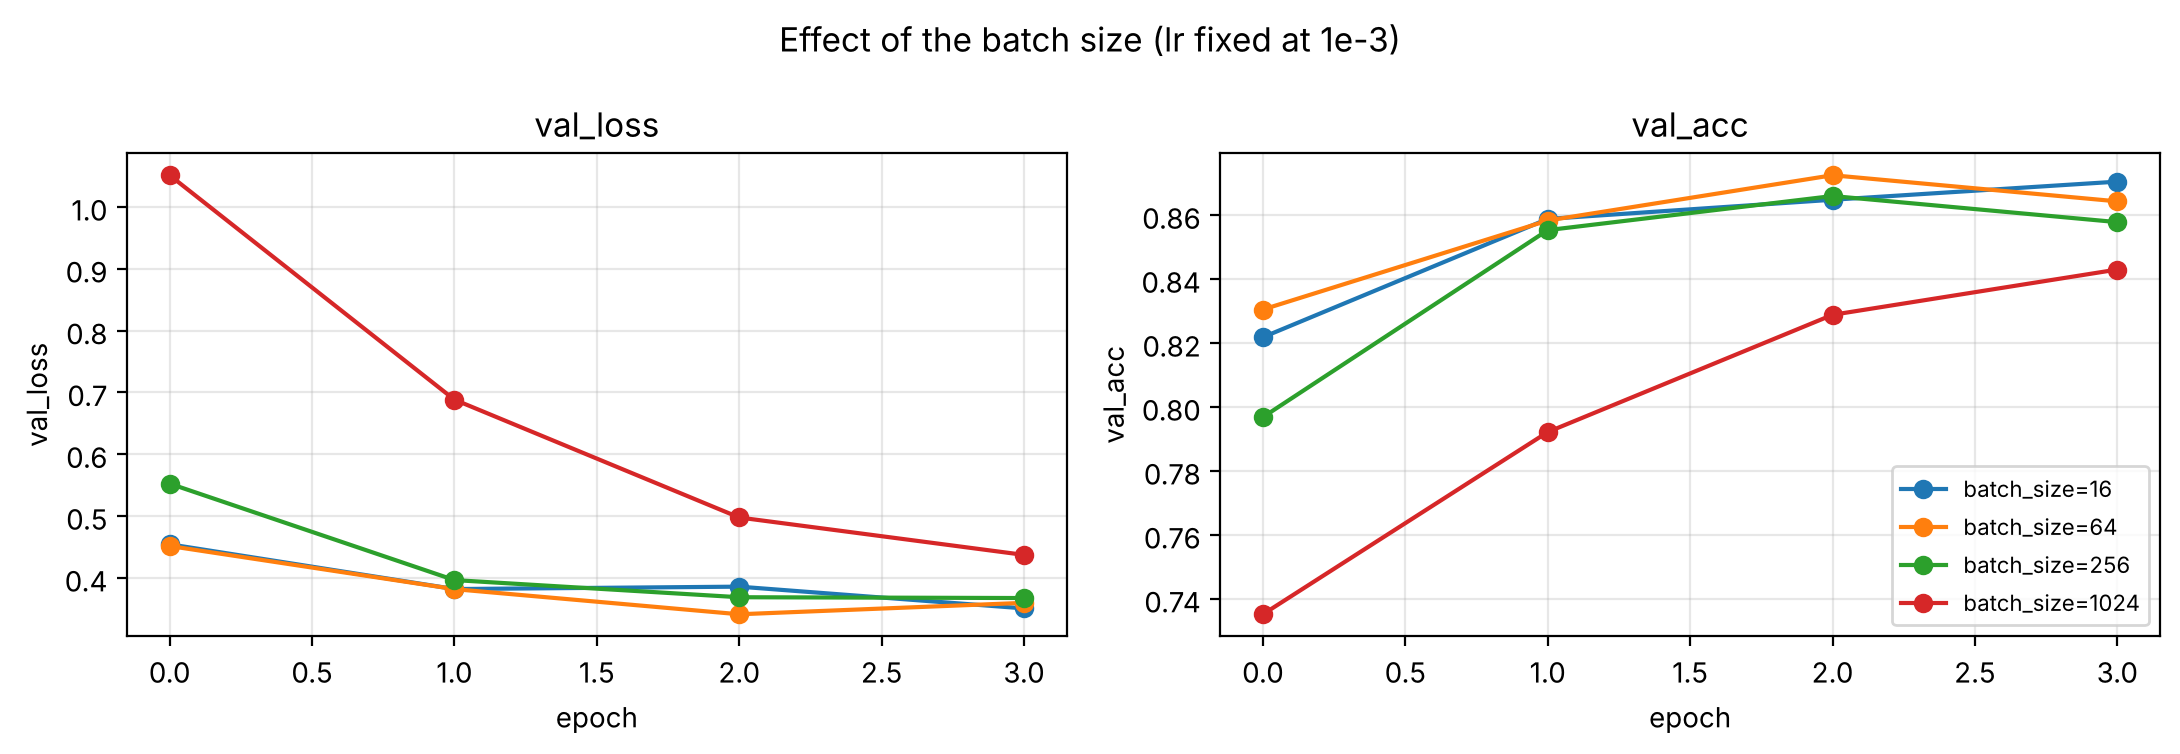

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
batch_size=16,0.8705,0.350730,0.326843,4,48.8
batch_size=64,0.8725,0.359716,0.316017,4,35.3
batch_size=256,0.8660,0.367477,0.372626,4,34.0
batch_size=1024,0.8430,0.437260,0.444254,4,39.3


In [15]:
bs_values = [16, 64, 256, 1024]
bs_results = run_configs("batch_size", {f"batch_size={v}": {"batch_size": v} for v in bs_values})
plot_runs(bs_results, "Effect of the batch size (lr fixed at 1e-3)")
summarize(bs_results)

### 6.3 Optimizer and momentum

Each optimizer is given a learning rate in its usual working range, because a rate that suits one optimizer does not suit another.

**What to look for:** plain SGD is the slowest to make progress; adding momentum closes much of the gap; Adam and AdamW get going fastest with little tuning. With enough tuning and epochs, SGD with momentum is often competitive, which is why it is still widely used.

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


SGD (lr=0.01)                best val_acc = 0.8293   (35s)
SGD + momentum 0.9 (lr=0.01) best val_acc = 0.8618   (35s)
Adam (lr=0.001)              best val_acc = 0.8725   (36s)
AdamW (lr=0.001, wd=0.01)    best val_acc = 0.8715   (36s)


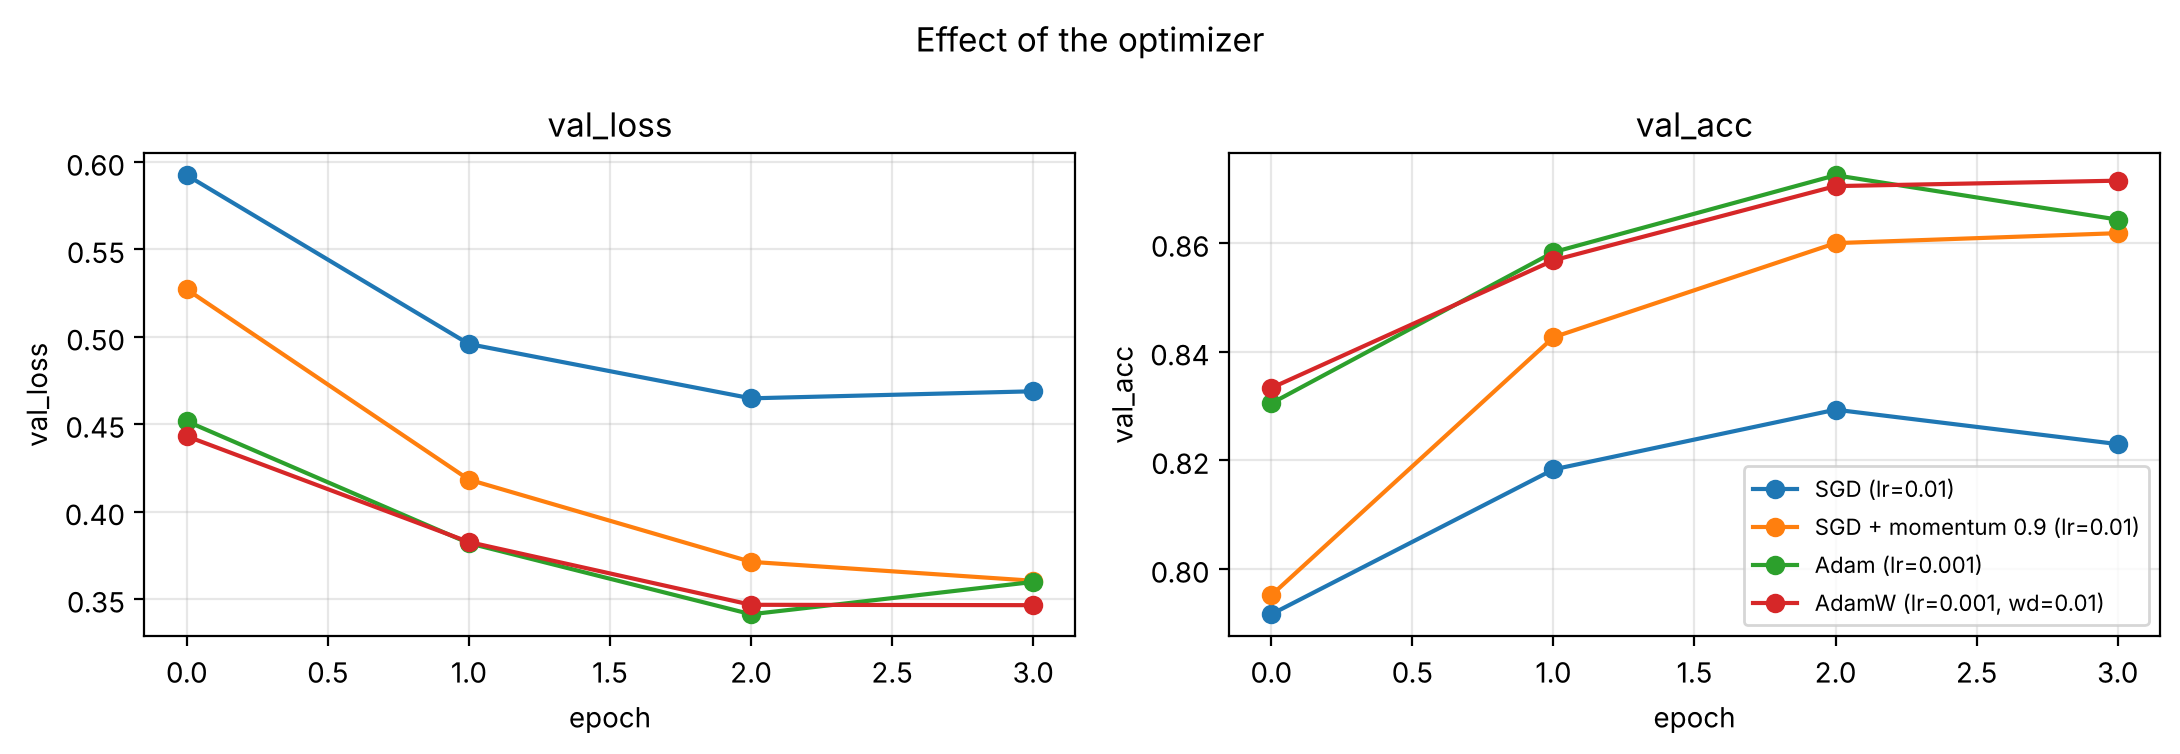

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
SGD (lr=0.01),0.829333,0.468812,0.452542,4,35.1
SGD + momentum 0.9 (lr=0.01),0.861833,0.360395,0.359327,4,35.0
Adam (lr=0.001),0.872500,0.359716,0.316017,4,35.5
"AdamW (lr=0.001, wd=0.01)",0.871500,0.346427,0.314530,4,36.0


In [16]:
optimizer_configs = {
    "SGD (lr=0.01)": {"optimizer": "sgd", "lr": 0.01, "momentum": 0.0},
    "SGD + momentum 0.9 (lr=0.01)": {"optimizer": "sgd", "lr": 0.01, "momentum": 0.9},
    "Adam (lr=0.001)": {"optimizer": "adam", "lr": 1e-3},
    "AdamW (lr=0.001, wd=0.01)": {"optimizer": "adamw", "lr": 1e-3, "weight_decay": 0.01},
}
opt_results = run_configs("optimizer", optimizer_configs)
plot_runs(opt_results, "Effect of the optimizer")
summarize(opt_results)

### 6.4 Regularisation: dropout, weight decay and augmentation

Regularisers only show their value when the model is able to **overfit**. To provoke that, this experiment uses just **2,000 training images** and trains for longer. A network with tens of thousands of weights can then start memorising the training set.

Each plot shows the training loss (dashed) and validation loss (solid) for one setting. The **gap** between them is the thing to watch:

- **No regularisation** — training loss heads towards zero while validation loss stalls or rises
- **Dropout / weight decay / augmentation** — training loss stays higher (the task was made harder on purpose), and the gap is smaller

A smaller gap is not automatically a better model; what counts in the end is the validation score itself. Too much regularisation causes underfitting.

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


no regularisation            best val_acc = 0.8555   (48s)
dropout=0.5                  best val_acc = 0.8545   (52s)
weight_decay=0.05 (AdamW)    best val_acc = 0.8577   (48s)
augmentation                 best val_acc = 0.8452   (55s)


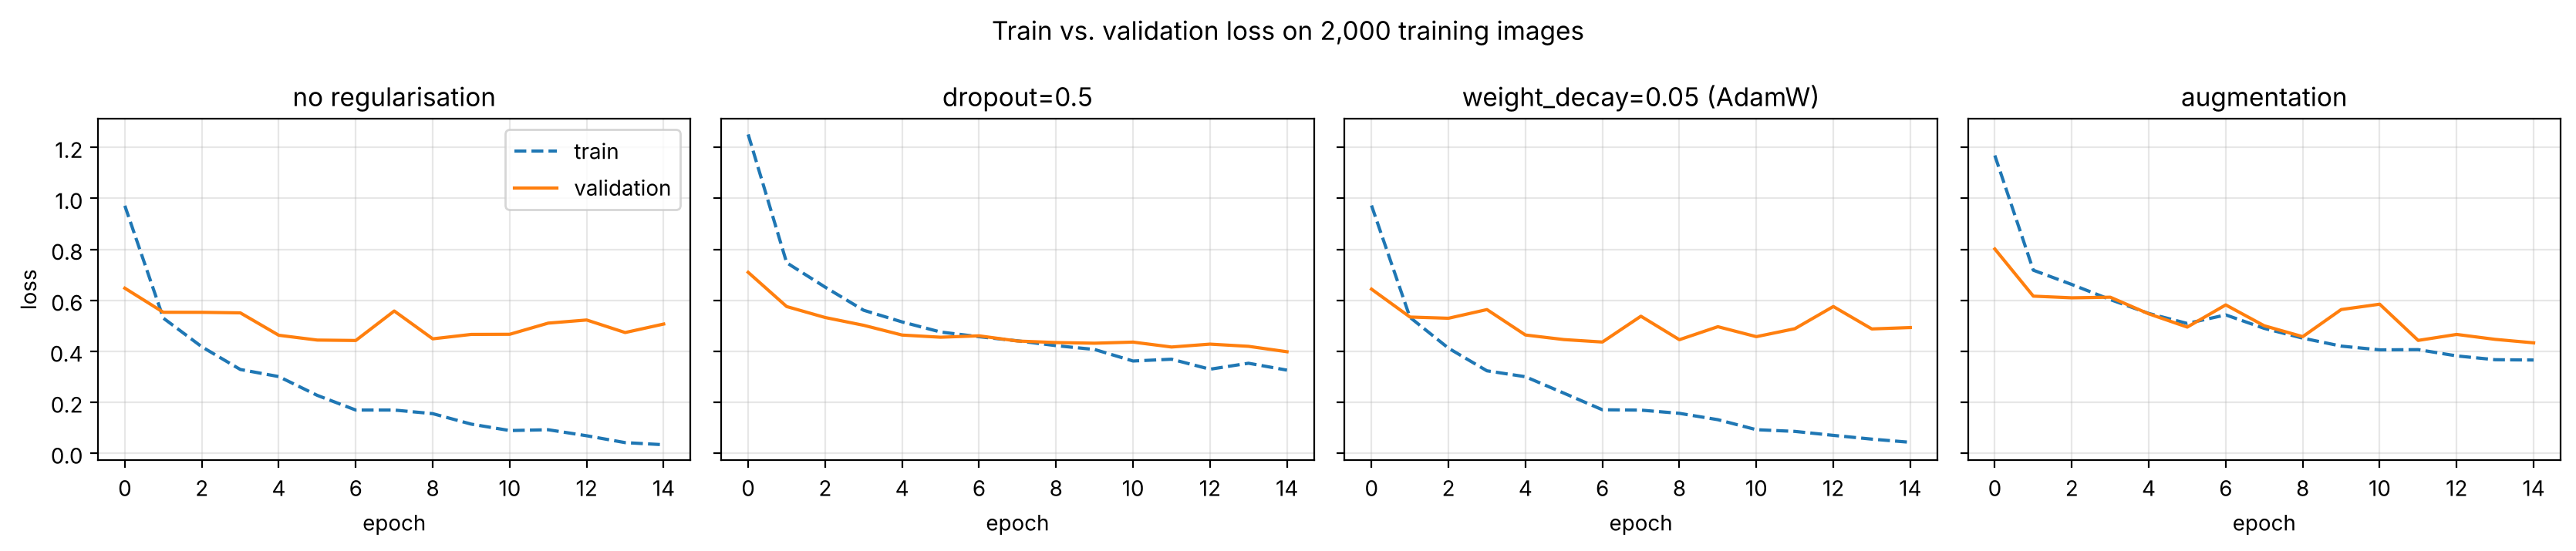

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
no regularisation,0.855500,0.506775,0.033094,15,48.5
dropout=0.5,0.854500,0.398105,0.325897,15,52.0
weight_decay=0.05 (AdamW),0.857667,0.493037,0.042593,15,47.6
augmentation,0.845167,0.433029,0.365630,15,54.7


In [17]:
OVERFIT = replace(HParams(), train_subset=2_000, max_epochs=15, patience=100, dropout=0.0)

reg_configs = {
    "no regularisation": {},
    "dropout=0.5": {"dropout": 0.5},
    "weight_decay=0.05 (AdamW)": {"optimizer": "adamw", "weight_decay": 0.05},
    "augmentation": {"augment": True},
}
reg_results = run_configs("regularisation", reg_configs, base=OVERFIT)

fig, axes = plt.subplots(1, len(reg_results), figsize=(4.2 * len(reg_results), 3.6), sharey=True)
for ax, (label, r) in zip(axes, reg_results.items()):
    h = r["history"]
    ax.plot(h["epoch"], h["train_loss"], "--", label="train")
    ax.plot(h["epoch"], h["val_loss"], "-", label="validation")
    ax.set(title=label, xlabel="epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("loss")
axes[0].legend()
fig.suptitle("Train vs. validation loss on 2,000 training images")
plt.tight_layout()
plt.show()

summarize(reg_results)

### 6.5 Model capacity

Finally, the width of the network. Remember the parameter counts from section 3.

**What to look for:** the tiny model has the lowest ceiling (underfitting); returns diminish as the model grows, while training time keeps climbing. On a larger, harder dataset the gap between sizes would be much wider.

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


tiny (8, 16, 32)             best val_acc = 0.8470   (15s)
default (32, 64, 128)        best val_acc = 0.8725   (36s)
wide (64, 128, 256)          best val_acc = 0.8848   (76s)


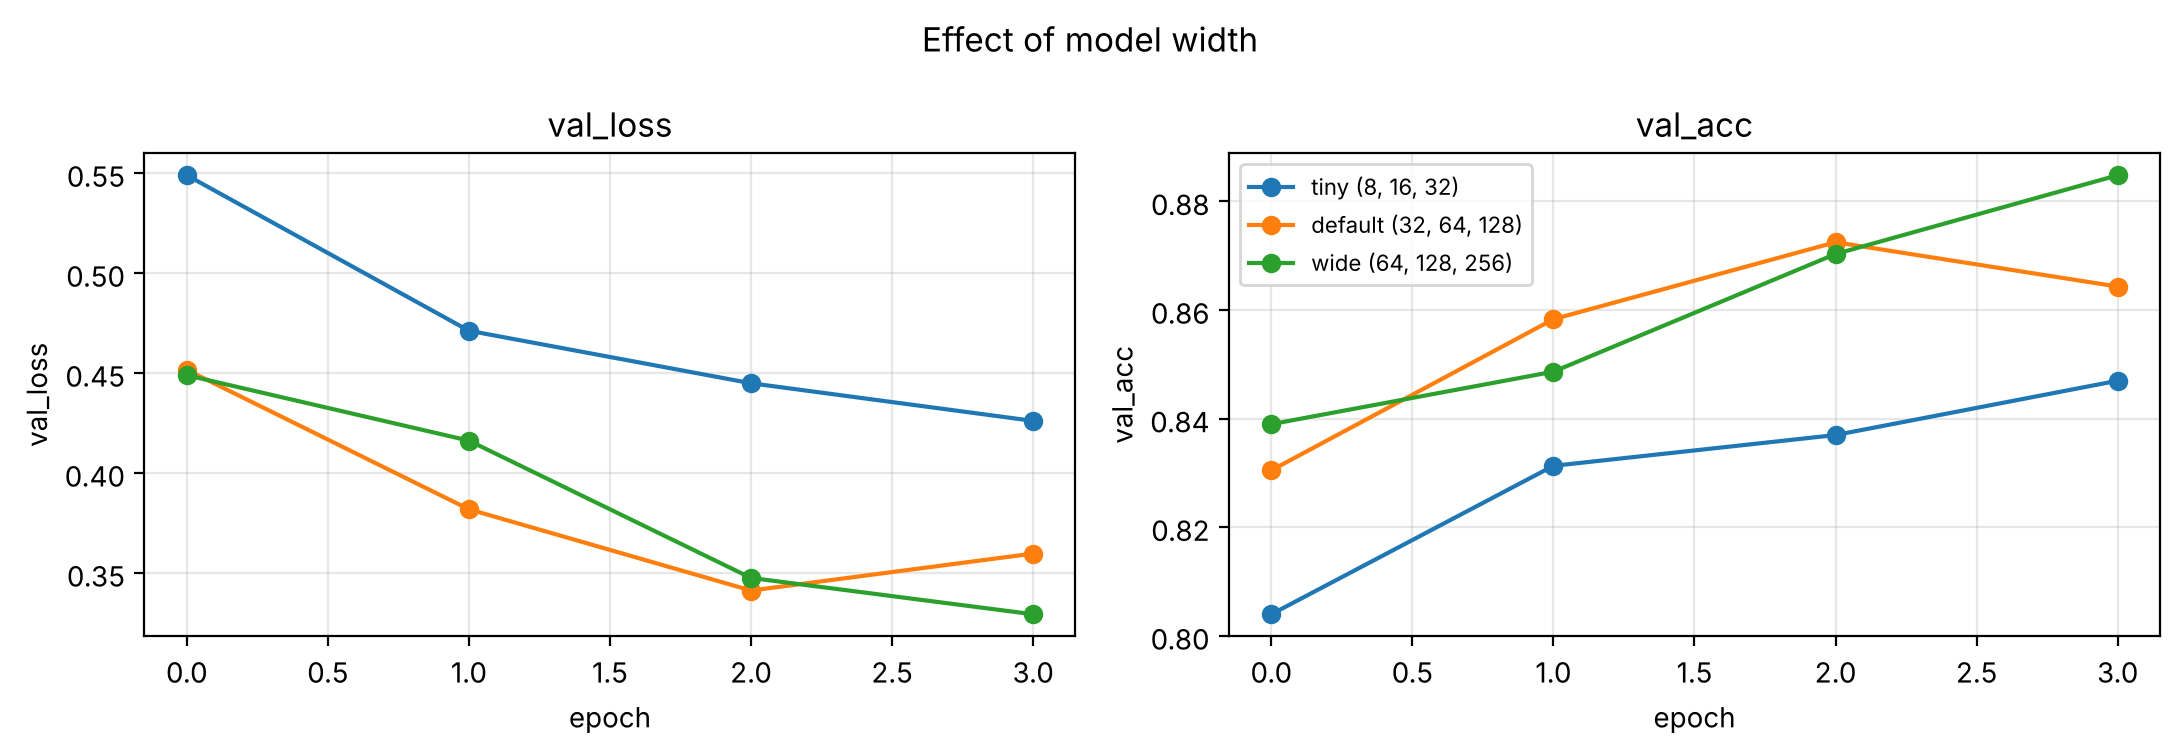

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
"tiny (8, 16, 32)",0.847000,0.426093,0.499605,4,15.4
"default (32, 64, 128)",0.872500,0.359716,0.316017,4,36.0
"wide (64, 128, 256)",0.884833,0.329351,0.316691,4,75.7


In [18]:
capacity_configs = {
    "tiny (8, 16, 32)": dict(conv1_channels=8, conv2_channels=16, hidden_dim=32),
    "default (32, 64, 128)": dict(),
    "wide (64, 128, 256)": dict(conv1_channels=64, conv2_channels=128, hidden_dim=256),
}
cap_results = run_configs("capacity", capacity_configs)
plot_runs(cap_results, "Effect of model width")
summarize(cap_results)

## 7. Searching several hyperparameters at once

Changing one thing at a time builds intuition, but hyperparameters **interact** (batch size with learning rate, dropout with model size), so the best combination is rarely the combination of individually best values.

Three common strategies:

| Strategy | How it works | Comment |
|---|---|---|
| **Grid search** | Try every combination of a few values per hyperparameter | Cost explodes: 4 hyperparameters × 5 values = 625 runs |
| **Random search** | Sample each hyperparameter independently from a range | Covers each individual axis much better for the same budget; a strong default |
| **Bayesian / adaptive** (e.g. Optuna, Ray Tune) | Use earlier results to pick promising configs and stop bad runs early | Most efficient when each run is expensive |

Below is a small **random search**. Note how each range is sampled:

- `lr` and `weight_decay` on a **log scale** (`10 ** uniform(a, b)`), because they span orders of magnitude
- `dropout` on a **linear scale**
- `batch_size` and `hidden_dim` from a **list of choices**

In [19]:
def sample_config(rng: random.Random) -> dict:
    return {
        "optimizer": "adamw",
        "lr": 10 ** rng.uniform(-4, -2),             # log-uniform in [1e-4, 1e-2]
        "weight_decay": 10 ** rng.uniform(-5, -1),   # log-uniform in [1e-5, 1e-1]
        "dropout": rng.uniform(0.0, 0.5),            # uniform
        "batch_size": rng.choice([32, 64, 128]),     # categorical
        "hidden_dim": rng.choice([64, 128, 256]),    # categorical
    }


N_TRIALS = 8
rng = random.Random(0)
trial_configs = {f"trial_{i}": sample_config(rng) for i in range(N_TRIALS)}

search_results = run_configs("random_search", trial_configs)

search_table = (
    pd.DataFrame(trial_configs).T
    .join(summarize(search_results)[["best_val_acc", "seconds"]])
    .sort_values("best_val_acc", ascending=False)
)
search_table

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


trial_0                      best val_acc = 0.8620   (39s)
trial_1                      best val_acc = 0.8672   (38s)
trial_2                      best val_acc = 0.8695   (38s)
trial_3                      best val_acc = 0.8702   (38s)
trial_4                      best val_acc = 0.8713   (35s)
trial_5                      best val_acc = 0.8577   (41s)
trial_6                      best val_acc = 0.8683   (35s)
trial_7                      best val_acc = 0.8732   (35s)


,optimizer,lr,weight_decay,dropout,batch_size,hidden_dim,best_val_acc,seconds
trial_7,adamw,0.000768,0.001217,0.03114,128,64,0.873167,35.1
trial_4,adamw,0.004173,0.040613,0.155074,128,64,0.871333,35.3
trial_3,adamw,0.003248,0.002975,0.125253,128,256,0.870167,37.8
trial_2,adamw,0.001468,0.042899,0.252343,64,64,0.869500,37.7
trial_6,adamw,0.000738,0.002777,0.456506,128,128,0.868333,34.8
trial_1,adamw,0.000937,0.047091,0.414926,64,128,0.867167,38.0
trial_0,adamw,0.004885,0.01076,0.210286,64,256,0.862000,39.1
trial_5,adamw,0.006276,0.005444,0.236071,32,128,0.857667,41.2


## 8. Final model and the one test evaluation

Take the best configuration from the search, train it on the **full** training set with the normal epoch budget and early stopping, and only then look at the **test** set. `ckpt_path="best"` reloads the weights from the epoch with the highest validation accuracy.

Everything up to this point was decided with validation data only, so the test accuracy below is an honest estimate.

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

  | Name    | Type             | Params | Mode  | FLOPs
-------------------------------------------------------------
0 | model   | SmallCNN         | 220 K  | train | 0    
1 | loss_fn | CrossEntropyLoss | 0      | train | 0    
-------------------------------------------------------------
220 K     Trainable params
0         Non-trainable params
220 K     Total params
0.882     Total estimated model params size (MB)
20        Modules in train mode
0         Modules in eval mode
0         Total Flops


best trial: trial_7
{'optimizer': 'adamw', 'lr': 0.0007680450920752482, 'weight_decay': 0.001217347411459147, 'dropout': 0.031139794010772603, 'batch_size': 128, 'hidden_dim': 64}


/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Epoch 4: 100%|██████████| 422/422 [00:38<00:00, 10.99it/s, v_num=0, val_loss=0.240, val_acc=0.914, train_loss=0.193, train_acc=0.930]


`Trainer.fit` stopped: `max_epochs=5` reached.


Epoch 4: 100%|██████████| 422/422 [00:38<00:00, 10.99it/s, v_num=0, val_loss=0.240, val_acc=0.914, train_loss=0.193, train_acc=0.930]


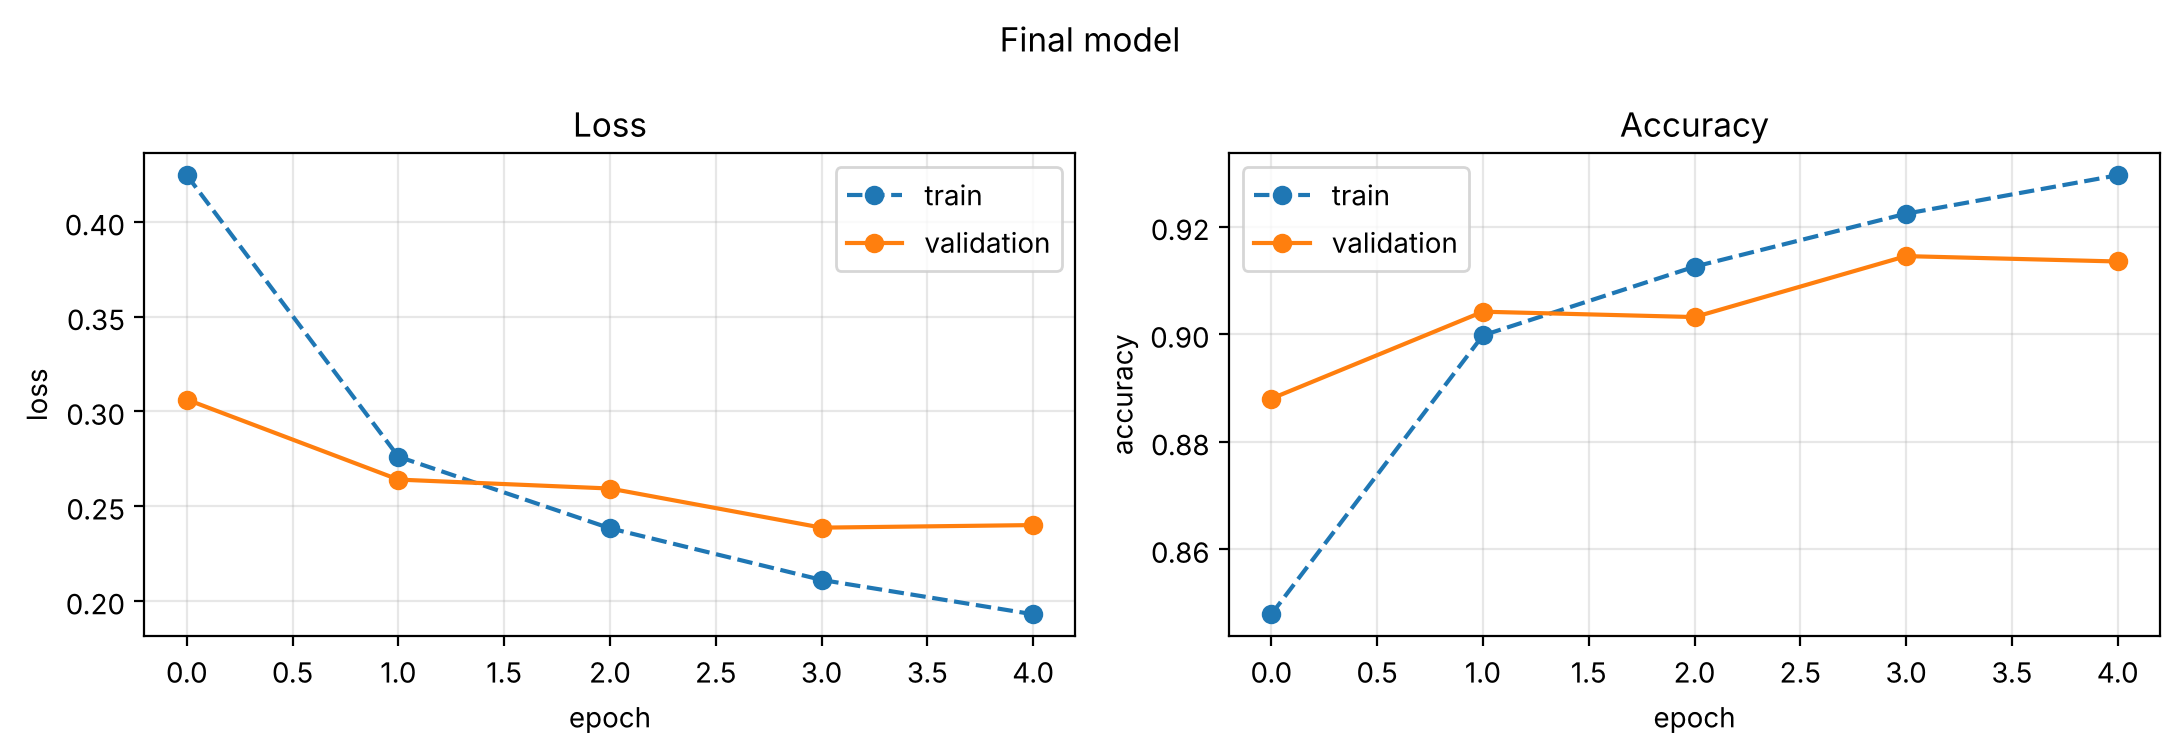

Restoring states from the checkpoint path at logs/final/version_0/checkpoints/epoch=3-step=1688.ckpt
Loaded model weights from the checkpoint at logs/final/version_0/checkpoints/epoch=3-step=1688.ckpt



────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test_acc            0.9085000157356262
        test_loss           0.24702201783657074
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

baseline best val_acc: 0.9152
final    best val_acc: 0.9145
final    test_acc:     0.9085


In [20]:
best_trial = search_table.index[0]
best_overrides = trial_configs[best_trial]
print("best trial:", best_trial)
print(best_overrides)

final_hp = replace(HParams(), **best_overrides)
trainer, model, dm, final_history = fit(final_hp, run_name="final", checkpoint=True)
plot_history(final_history, "Final model")

test_metrics = trainer.test(model, datamodule=dm, ckpt_path="best")
print(f"\nbaseline best val_acc: {baseline_history['val_acc'].max():.4f}")
print(f"final    best val_acc: {final_history['val_acc'].max():.4f}")
print(f"final    test_acc:     {test_metrics[0]['test_acc']:.4f}")

## 9. Summary

**The hyperparameters in this notebook, in rough order of how much attention they deserve**

| Priority | Hyperparameter | Typical starting point | Search scale |
|---|---|---|---|
| 1 | Learning rate | `1e-3` (Adam/AdamW), `1e-2`–`1e-1` (SGD + momentum) | log |
| 2 | Optimizer, momentum | AdamW, or SGD with momentum 0.9 | categorical |
| 3 | Batch size | 32–256, limited by memory; retune `lr` when you change it | powers of two |
| 4 | Epochs / early stopping | Generous `max_epochs` with `patience` 3–10 | — |
| 5 | Model width and depth | Smallest model that can fit the training set, then grow | powers of two |
| 6 | Dropout | 0.1–0.5 | linear |
| 7 | Weight decay | `1e-4`–`1e-2` | log |
| 8 | Scheduler, augmentation | Cosine; light crops/flips | categorical |

**A practical workflow**

1. Get a simple baseline running end to end and record its validation score.
2. Tune the learning rate first, on a log scale. Most "my model does not learn" problems end here.
3. Make the model big enough to fit (even overfit) the training data.
4. Add regularisation until validation performance stops improving.
5. Run a random search around the promising region; confirm the winner with a second seed.
6. Touch the test set once.

**Exercises**

1. Rerun the baseline with three different `seed` values. How large is the spread in `val_acc`? Which differences in section 6 are larger than that spread?
2. Repeat the learning-rate experiment with `optimizer="sgd"`. Does the best rate move?
3. In the batch-size experiment, scale `lr` with the batch size (for example `lr = 1e-3 * batch_size / 64`). Does the large-batch run catch up?
4. Compare `scheduler="none"`, `"step"` and `"cosine"` with `max_epochs=10`.
5. Switch `use_batchnorm` off and repeat the learning-rate experiment. Is the model more or less sensitive to `lr`?
6. Add a `num_conv_blocks` field to `HParams` and make depth tunable in `SmallCNN`.
7. Swap `datasets.FashionMNIST` for `datasets.CIFAR10` (3 input channels, 32×32 images). Which hyperparameters need to change?

---
# Exercise solutions

## Exercise 1 — Seed spread

Rerun the baseline with three different `seed` values and measure how far apart the `val_acc` values are.

In [21]:
seed_values = [1, 2, 3]

# (a) the full baseline
seed_results = run_configs("ex1_seed_baseline",
                           {f"seed={s}": {"seed": s} for s in seed_values},
                           base=HParams())

# (b) the FAST config
seed_results_fast = run_configs("ex1_seed_fast",
                                {f"seed={s}": {"seed": s} for s in seed_values},
                                base=FAST)


def spread(results):
    """Difference between the best and the worst run (max - min of best val_acc)."""
    accs = [r["history"]["val_acc"].max() for r in results.values()]
    return max(accs) - min(accs)


spread_baseline = spread(seed_results)
spread_fast = spread(seed_results_fast)
print(f"\nspread, full baseline : {spread_baseline:.4f}  ({spread_baseline * 100:.2f} percentage points)")
print(f"spread, FAST config   : {spread_fast:.4f}  ({spread_fast * 100:.2f} percentage points)")


section6 = {
    "6.1 learning rate": lr_results,
    "6.2 batch size": bs_results,
    "6.3 optimizer": opt_results,
    "6.4 regularisation": reg_results,
    "6.5 capacity": cap_results,
}
rows = []
for name, res in section6.items():
    accs = {label: r["history"]["val_acc"].max() for label, r in res.items()}
    best, worst = max(accs, key=accs.get), min(accs, key=accs.get)
    diff = accs[best] - accs[worst]
    rows.append({"experiment": name, "best run": best, "worst run": worst,
                 "best - worst": round(diff, 4),
                 "x seed spread": round(diff / spread_fast, 1),
                 "larger than seed spread?": diff > spread_fast})
ex1_table = pd.DataFrame(rows).set_index("experiment")
ex1_table

seed=1                       best val_acc = 0.9233   (209s)
seed=2                       best val_acc = 0.9210   (208s)
seed=3                       best val_acc = 0.9173   (204s)
seed=1                       best val_acc = 0.8872   (37s)
seed=2                       best val_acc = 0.8823   (36s)
seed=3                       best val_acc = 0.8762   (37s)

spread, full baseline : 0.0060  (0.60 percentage points)
spread, FAST config   : 0.0110  (1.10 percentage points)


,best run,worst run,best - worst,x seed spread,larger than seed spread?
experiment,,,,,
6.1 learning rate,lr=0.001,lr=0.1,0.1847,16.8,True
6.2 batch size,batch_size=64,batch_size=1024,0.0295,2.7,True
6.3 optimizer,Adam (lr=0.001),SGD (lr=0.01),0.0432,3.9,True
6.4 regularisation,weight_decay=0.05 (AdamW),augmentation,0.0125,1.1,True
6.5 capacity,"wide (64, 128, 256)","tiny (8, 16, 32)",0.0378,3.4,True


With seeds 1, 2 and 3 the full baseline gave `val_acc` = 0.9233, 0.9210 and 0.9173, a spread of **0.60 percentage points**. The FAST config used in section 6 gave 0.8872, 0.8823 and 0.8762, a spread of **1.10 points** (less data and fewer epochs, so more noise). The seed-42 FAST run from section 6 scored 0.8725, which is even lower, so about 1 point is the noise level.

Differences in section 6 that are clearly larger than the spread: every learning rate other than 1e-3 (1.7 to 18.5 points below the best), batch size 1024 (2.95), plain SGD without momentum (4.3) and the tiny model (3.8). Differences that are within the noise: batch sizes 16, 64 and 256 (at most 0.65), Adam vs AdamW (0.1), SGD with momentum vs Adam (1.07), and the regularisation runs (0.2 to 0.3; augmentation at 1.25 and default vs wide at 1.23 are only just above the spread).

In [22]:
rows = []
for name, res in section6.items():
    accs = {label: r["history"]["val_acc"].max() for label, r in res.items()}
    top = max(accs.values())
    for label, acc in accs.items():
        rows.append({"experiment": name, "run": label, "best_val_acc": round(acc, 4),
                     "gap to best": round(top - acc, 4),
                     "gap > seed spread?": (top - acc) > spread_fast})
ex1_detail = pd.DataFrame(rows).set_index(["experiment", "run"])
ex1_detail

best_val_acc  gap to best  \
experiment         run                                                       
6.1 learning rate  lr=1e-05                            0.7745       0.0980   
                   lr=0.0001                           0.8552       0.0173   
                   lr=0.001                            0.8725       0.0000   
                   lr=0.01                             0.8505       0.0220   
                   lr=0.1                              0.6878       0.1847   
6.2 batch size     batch_size=16                       0.8705       0.0020   
                   batch_size=64                       0.8725       0.0000   
                   batch_size=256                      0.8660       0.0065   
                   batch_size=1024                     0.8430       0.0295   
6.3 optimizer      SGD (lr=0.01)                       0.8293       0.0432   
                   SGD + momentum 0.9 (lr=0.01)        0.8618       0.0107   
                   Adam (lr=0.001)                     0.8725       0.0000   
                   AdamW (lr=0.001, wd=0.01)           0.8715       0.0010   
6.4 regularisation no regularisation                   0.8555       0.0022   
                   dropout=0.5                         0.8545       0.0032   
                   weight_decay=0.05 (AdamW)           0.8577       0.0000   
                   augmentation                        0.8452       0.0125   
6.5 capacity       tiny (8, 16, 32)                    0.8470       0.0378   
                   default (32, 64, 128)               0.8725       0.0123   
                   wide (64, 128, 256)                 0.8848       0.0000   

                                                 gap > seed spread?  
experiment         run                                               
6.1 learning rate  lr=1e-05                                    True  
                   lr=0.0001                                   True  
                   lr=0.001                                   False  
                   lr=0.01                                     True  
                   lr=0.1                                      True  
6.2 batch size     batch_size=16                              False  
                   batch_size=64                              False  
                   batch_size=256                             False  
                   batch_size=1024                             True  
6.3 optimizer      SGD (lr=0.01)                               True  
                   SGD + momentum 0.9 (lr=0.01)               False  
                   Adam (lr=0.001)                            False  
                   AdamW (lr=0.001, wd=0.01)                  False  
6.4 regularisation no regularisation                          False  
                   dropout=0.5                                False  
                   weight_decay=0.05 (AdamW)                  False  
                   augmentation                                True  
6.5 capacity       tiny (8, 16, 32)                            True  
                   default (32, 64, 128)                       True  
                   wide (64, 128, 256)                        False

## Exercise 2 — Learning-rate experiment with SGD

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=1e-05                     best val_acc = 0.5907   (38s)
lr=0.0001                    best val_acc = 0.7653   (37s)
lr=0.001                     best val_acc = 0.8477   (36s)
lr=0.01                      best val_acc = 0.8618   (34s)
lr=0.1                       best val_acc = 0.8102   (37s)


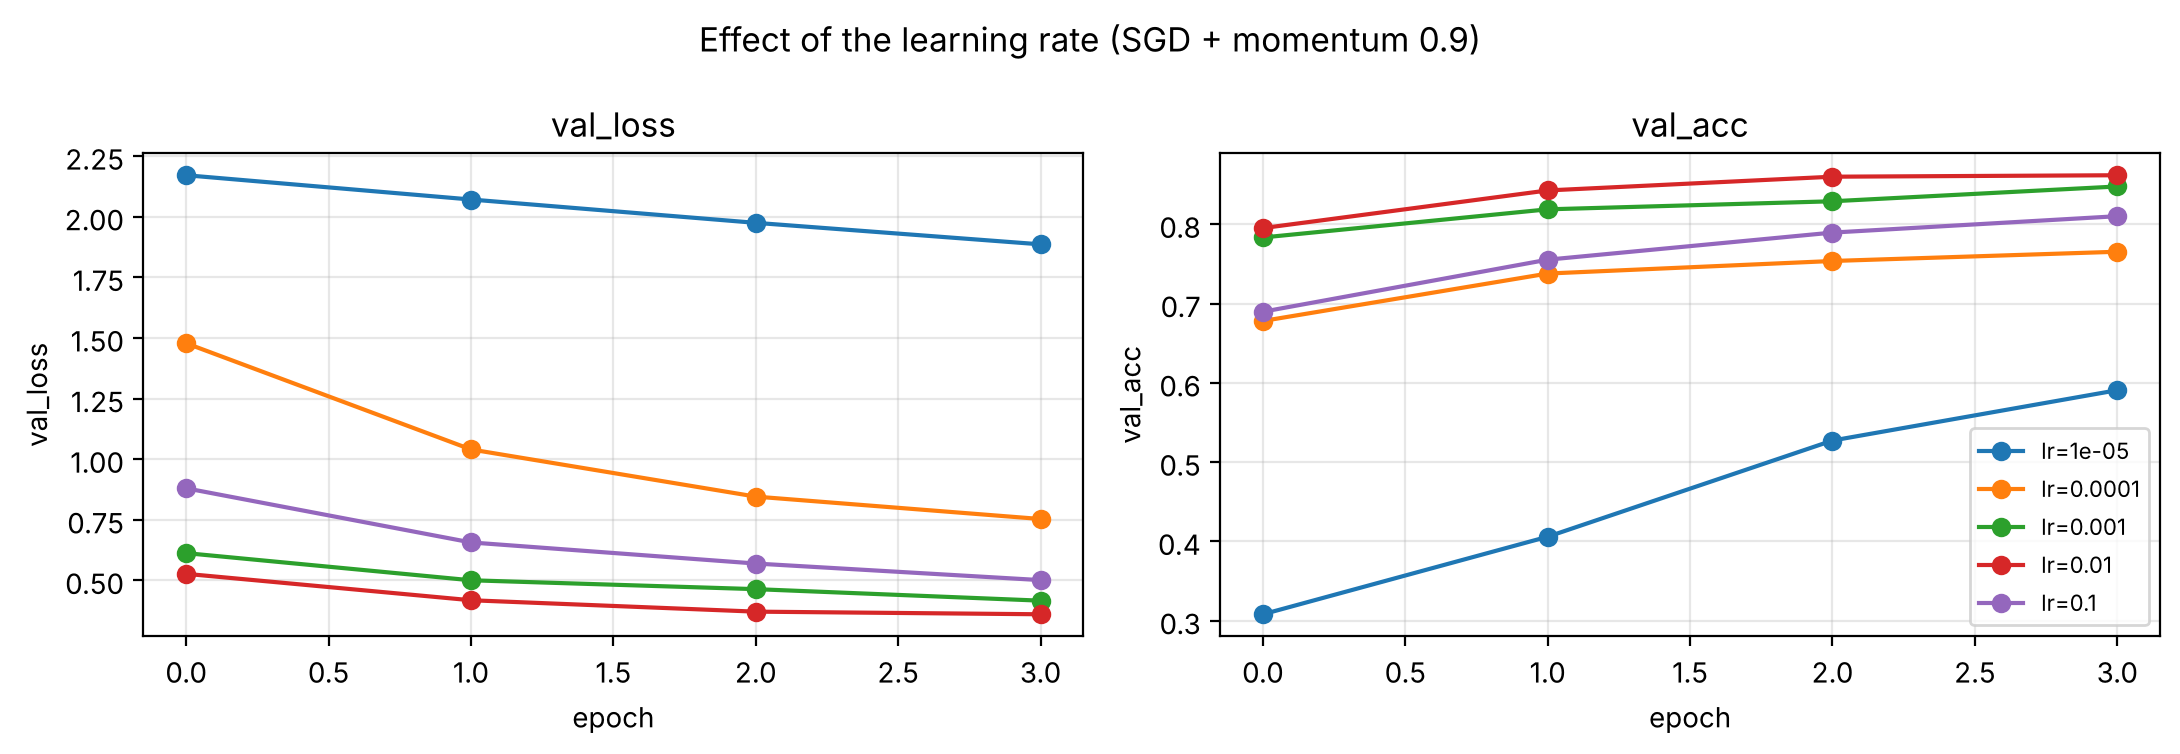

best lr for Adam: lr=0.001
best lr for SGD : lr=0.01


,Adam best_val_acc,SGD best_val_acc,Adam final_val_loss,SGD final_val_loss
run,,,,
lr=1e-05,0.774500,0.590667,0.707266,1.886247
lr=0.0001,0.855167,0.765333,0.393514,0.753332
lr=0.001,0.872500,0.847667,0.359716,0.416555
lr=0.01,0.850500,0.861833,0.418487,0.360395
lr=0.1,0.687833,0.810167,0.844341,0.501345


In [23]:
lr_results_sgd = run_configs("ex2_lr_sgd",
                             {f"lr={v:g}": {"lr": v, "optimizer": "sgd"} for v in lr_values})
plot_runs(lr_results_sgd, "Effect of the learning rate (SGD + momentum 0.9)")

ex2_table = pd.DataFrame({
    "Adam best_val_acc": summarize(lr_results)["best_val_acc"],
    "SGD best_val_acc": summarize(lr_results_sgd)["best_val_acc"],
    "Adam final_val_loss": summarize(lr_results)["final_val_loss"],
    "SGD final_val_loss": summarize(lr_results_sgd)["final_val_loss"],
})
print("best lr for Adam:", ex2_table["Adam best_val_acc"].idxmax())
print("best lr for SGD :", ex2_table["SGD best_val_acc"].idxmax())
ex2_table

Yes, the best rate moves up by a factor of 10: Adam was best at `lr=1e-3` (0.8725) and SGD is best at `lr=1e-2` (0.8618). SGD needs bigger steps because it does not rescale the step per parameter. At small rates SGD is far behind (0.5907 vs 0.7745 at 1e-5), but at `lr=0.1` it still reaches 0.8102 while Adam drops to 0.6878. So a good learning rate does not transfer from one optimizer to another.

## Exercise 3 — Scale the learning rate with the batch size

Here `lr = 1e-3 * batch_size / 64`, so batch 64 is unchanged and bigger batches take bigger steps.

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


batch_size=16                best val_acc = 0.8702   (50s)
batch_size=64                best val_acc = 0.8725   (37s)
batch_size=256               best val_acc = 0.8543   (34s)
batch_size=1024              best val_acc = 0.6845   (44s)


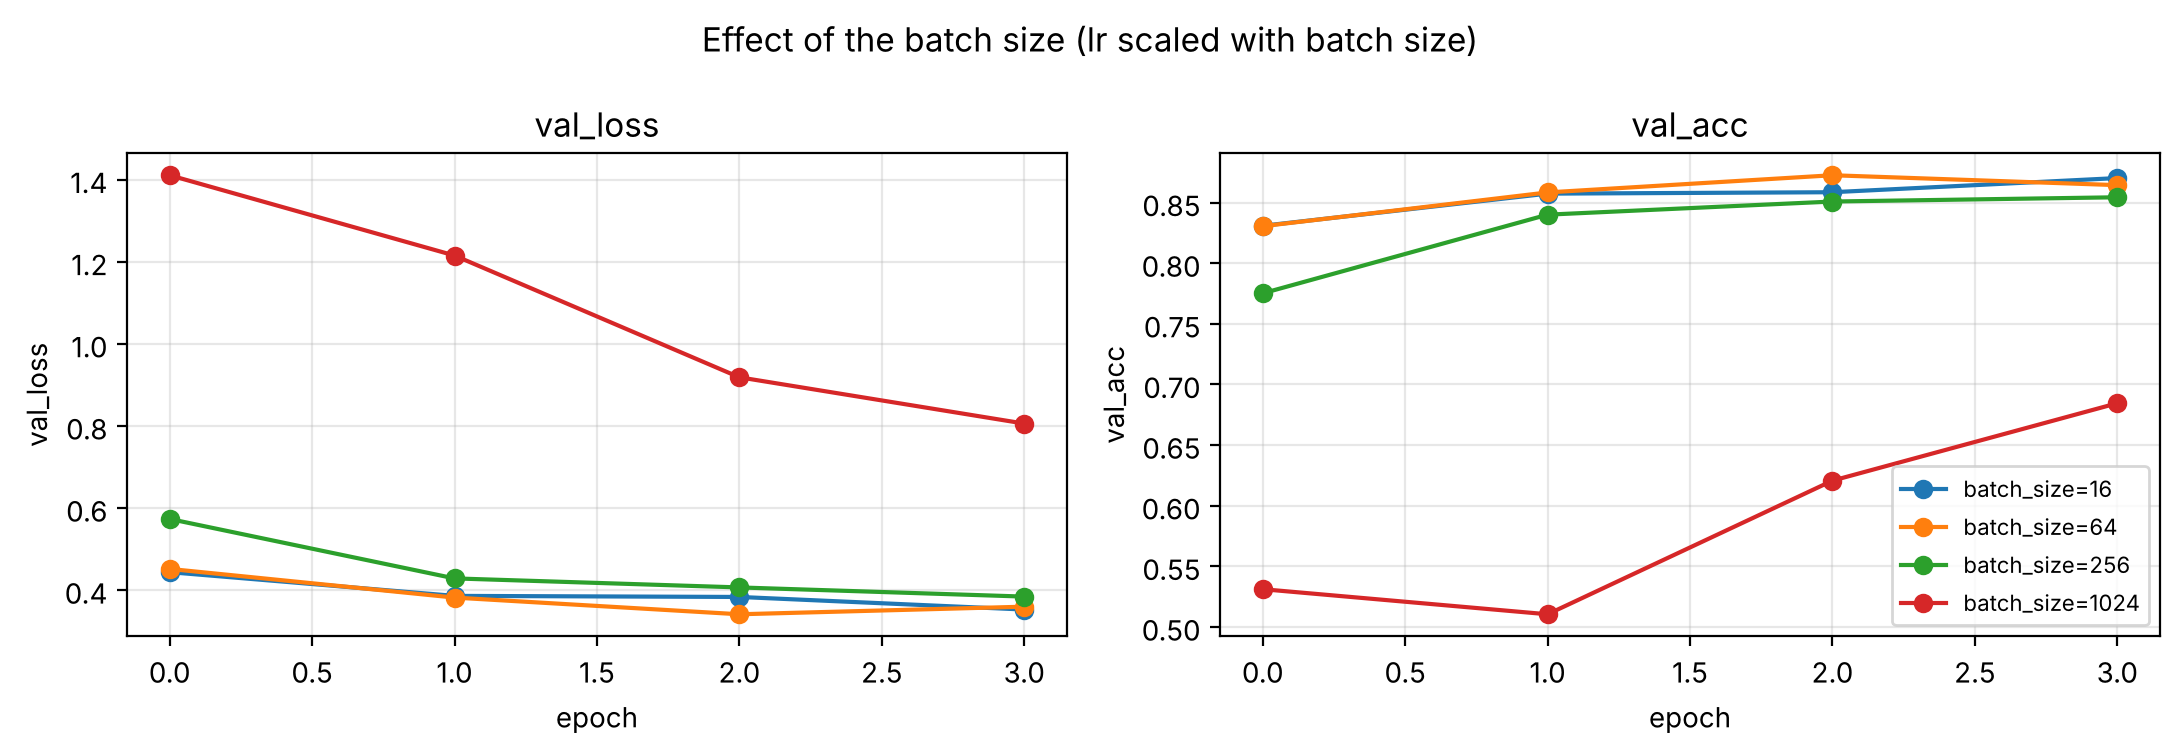

,lr used (scaled),"val_acc, fixed lr=1e-3","val_acc, scaled lr",change
batch_size=16,0.00025,0.8705,0.870167,-0.000333
batch_size=64,0.00100,0.8725,0.872500,0.000000
batch_size=256,0.00400,0.8660,0.854333,-0.011667
batch_size=1024,0.01600,0.8430,0.684500,-0.158500


In [24]:
bs_scaled_configs = {
    f"batch_size={v}": {"batch_size": v, "lr": 1e-3 * v / 64} for v in bs_values
}
bs_results_scaled = run_configs("ex3_bs_scaled_lr", bs_scaled_configs)
plot_runs(bs_results_scaled, "Effect of the batch size (lr scaled with batch size)")

ex3_table = pd.DataFrame({
    "lr used (scaled)": {label: cfg["lr"] for label, cfg in bs_scaled_configs.items()},
    "val_acc, fixed lr=1e-3": summarize(bs_results)["best_val_acc"],
    "val_acc, scaled lr": summarize(bs_results_scaled)["best_val_acc"],
})
ex3_table["change"] = ex3_table["val_acc, scaled lr"] - ex3_table["val_acc, fixed lr=1e-3"]
ex3_table

No, the large-batch run did not catch up. It got worse: batch 1024 went from 0.8430 (fixed lr) to 0.6845 with `lr=0.016`, and batch 256 went from 0.8660 to 0.8543 with `lr=0.004`. Batch 16 with the smaller `lr=0.00025` was unchanged (0.8702). The scaled rates are larger than what Adam tolerates here (section 6.1 already showed Adam losing accuracy at 0.01), and batch 1024 only makes 40 updates in 4 epochs, so there is no time to recover from the unstable start. The linear scaling rule comes from SGD and usually needs a warm-up; with Adam on this model it overshoots.

## Exercise 4 — Schedulers with `max_epochs=10`

`none` keeps `lr = 1e-3` the whole time. `step` divides it by 10 every 3 epochs (`max_epochs // 3`). `cosine` lowers it smoothly to zero by the last epoch.

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


scheduler=none               best val_acc = 0.8922   (94s)
scheduler=step               best val_acc = 0.8903   (91s)
scheduler=cosine             best val_acc = 0.9028   (89s)


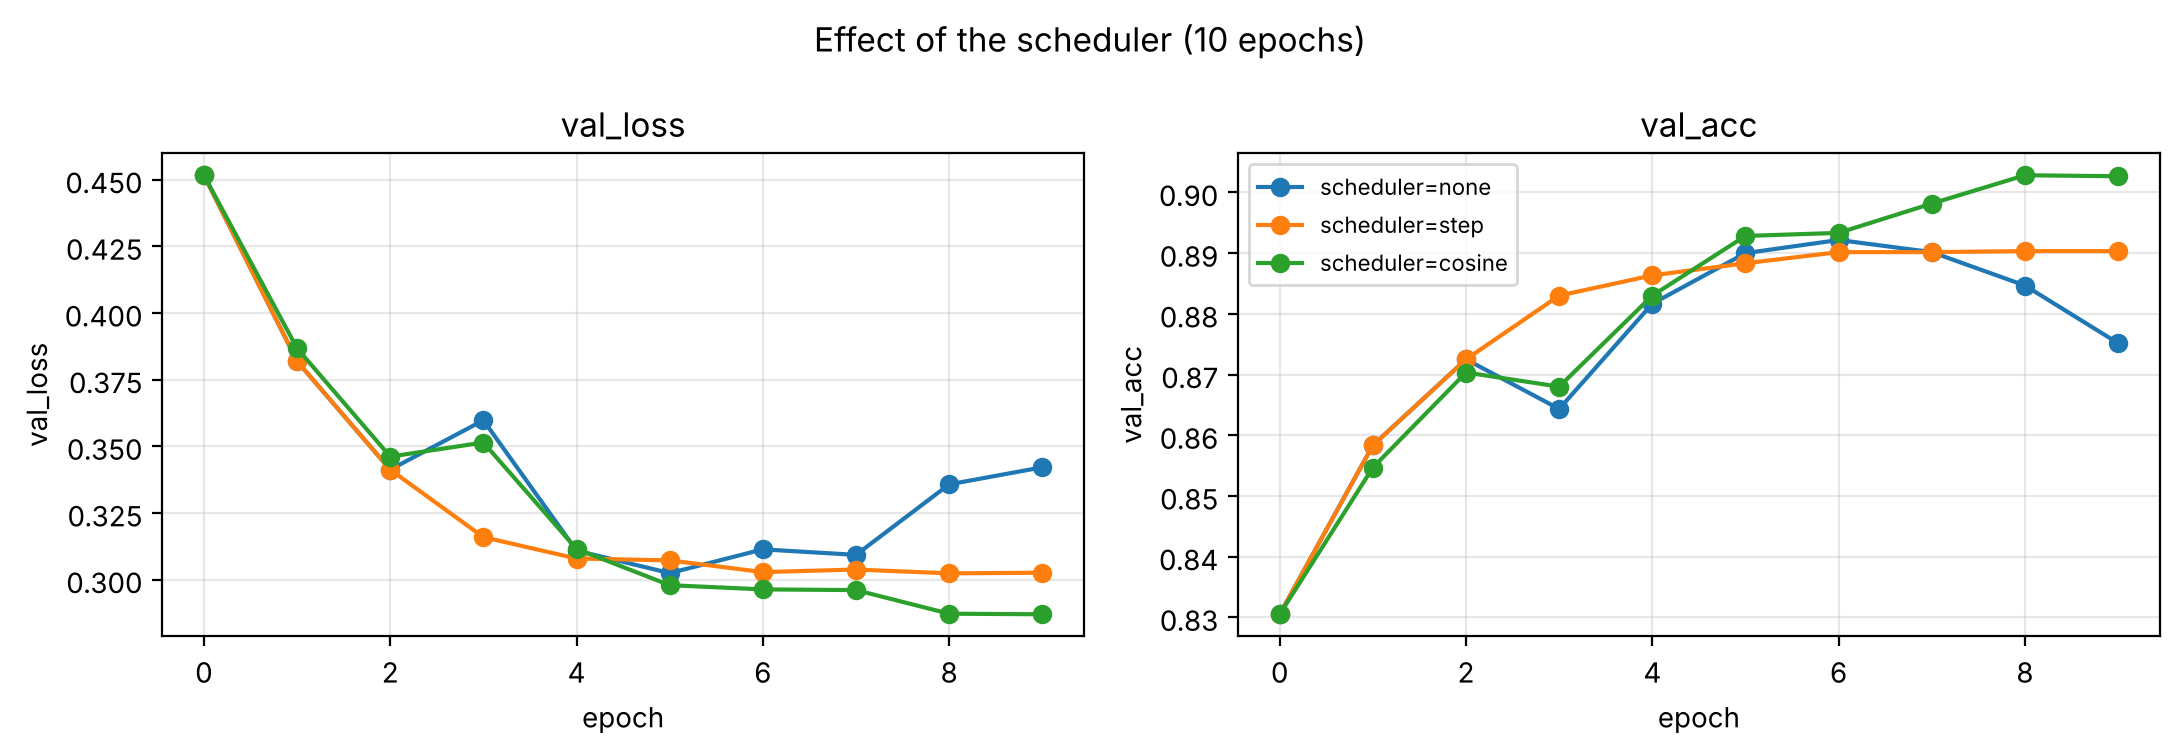

   scheduler=none  scheduler=step  scheduler=cosine
0          0.8305          0.8305            0.8305
1          0.8583          0.8583            0.8547
2          0.8725          0.8725            0.8703
3          0.8643          0.8830            0.8680
4          0.8817          0.8863            0.8830
5          0.8900          0.8883            0.8928
6          0.8922          0.8902            0.8933
7          0.8902          0.8902            0.8982
8          0.8847          0.8903            0.9028
9          0.8752          0.8903            0.9027


,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
scheduler=none,0.892167,0.342086,0.209528,10,93.5
scheduler=step,0.890333,0.302556,0.234095,10,90.6
scheduler=cosine,0.902833,0.286964,0.166635,10,89.3


In [25]:
SCHED_BASE = replace(FAST, max_epochs=10)
sched_results = run_configs("ex4_scheduler",
                            {f"scheduler={s}": {"scheduler": s} for s in ["none", "step", "cosine"]},
                            base=SCHED_BASE)
plot_runs(sched_results, "Effect of the scheduler (10 epochs)")


print(pd.DataFrame({label: r["history"]["val_acc"].round(4) for label, r in sched_results.items()}))
summarize(sched_results)

Cosine was best: best `val_acc` 0.9028 and lowest final `val_loss` 0.287. With no scheduler the model peaked at 0.8922 in epoch 6 and then fell back to 0.8752, with the highest final `val_loss` (0.342), because the constant rate keeps taking big steps. Step reached 0.8903 and then went flat, because after two cuts the rate is 1e-5 and the model barely moves. The gap in best `val_acc` between cosine and none (1.07 points) is about the size of the seed spread, but at the last epoch the gap is 2.75 points, so the main benefit of a decaying rate is a stable finish.

## Exercise 5 — Learning-rate experiment without batch norm

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=1e-05                     best val_acc = 0.7127   (31s)
lr=0.0001                    best val_acc = 0.8027   (33s)
lr=0.001                     best val_acc = 0.8563   (33s)
lr=0.01                      best val_acc = 0.8438   (30s)
lr=0.1                       best val_acc = 0.1053   (32s)


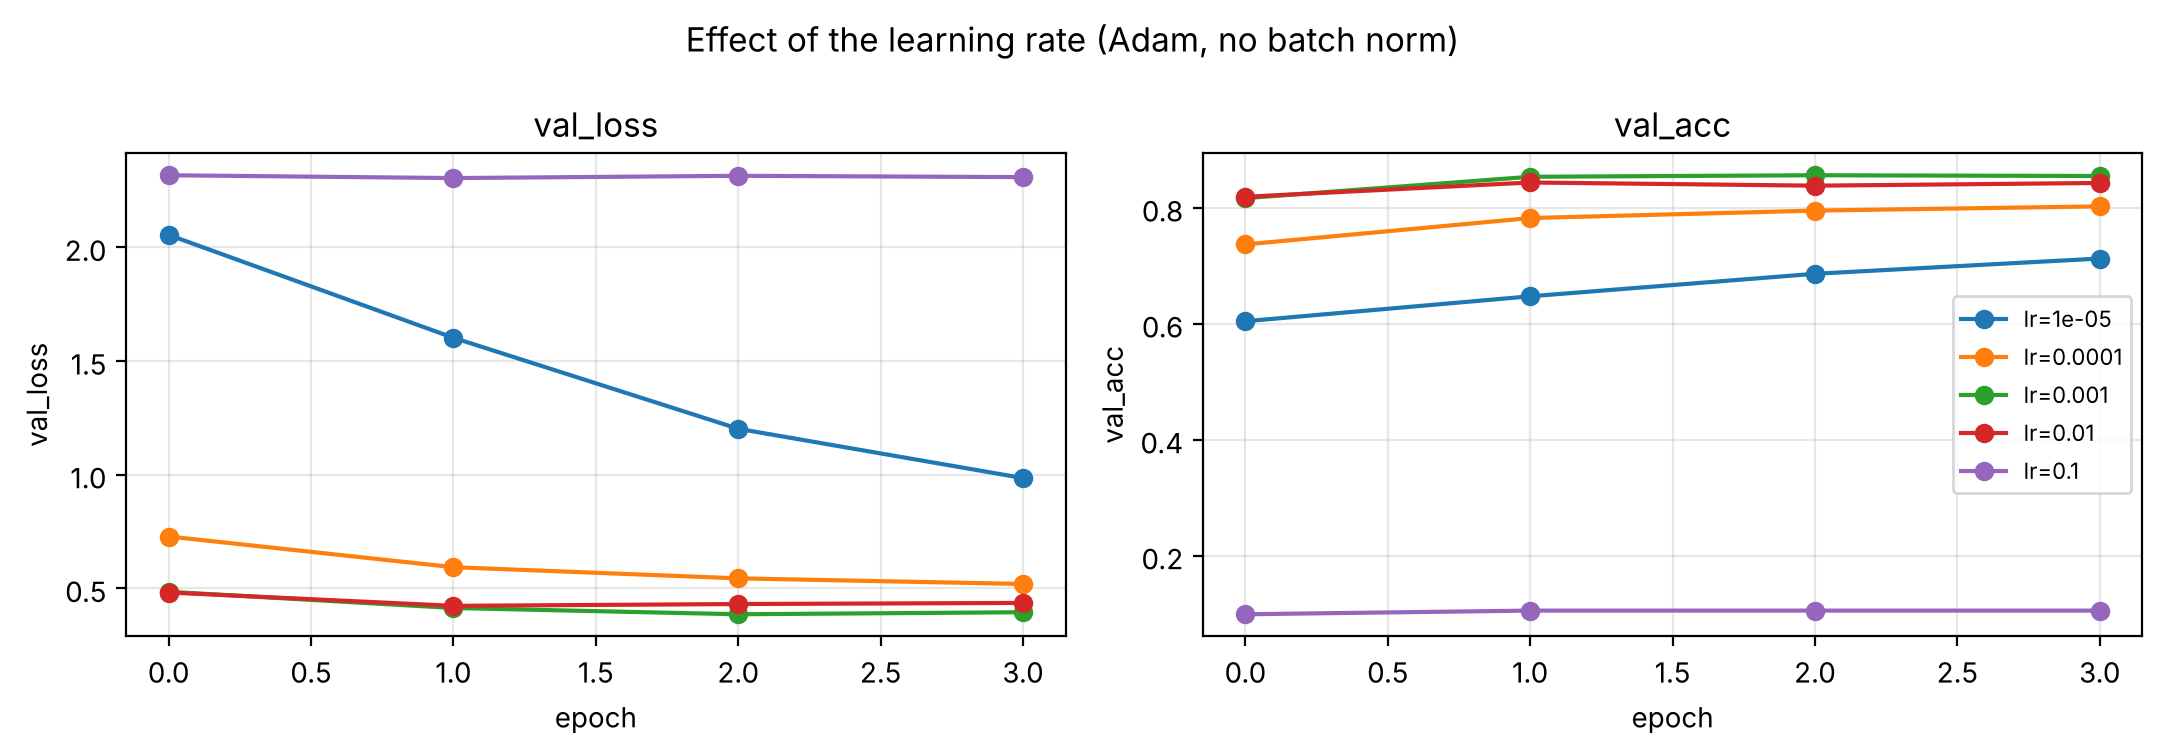

range of best_val_acc across lr, with BN: 0.1847
range of best_val_acc across lr, no BN  : 0.751


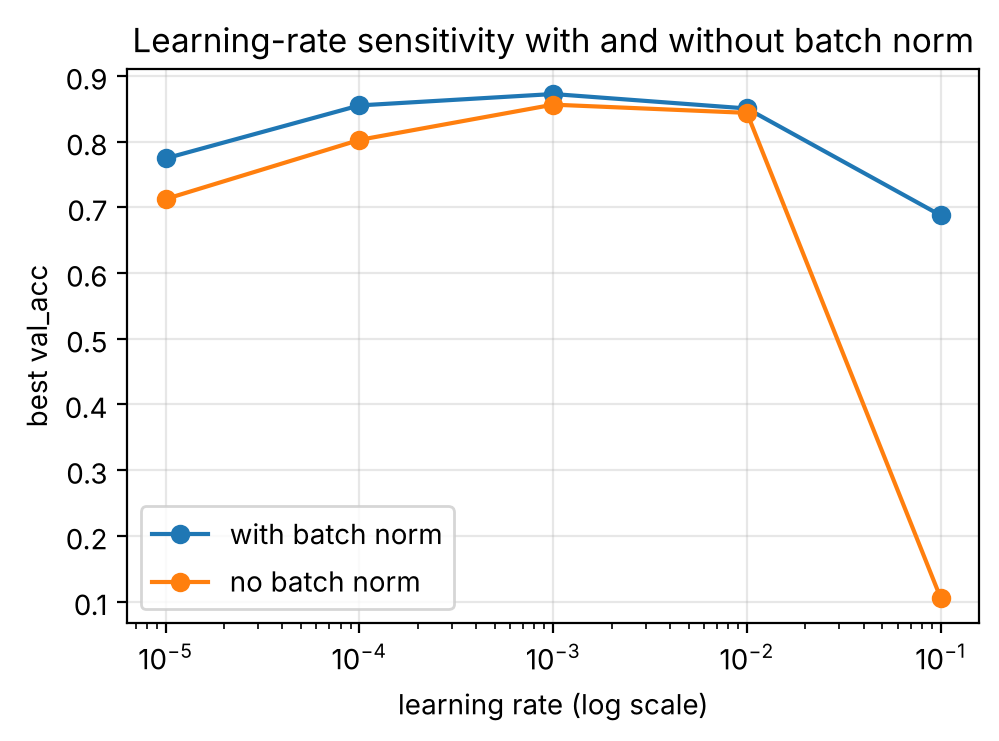

,with BN: best_val_acc,no BN: best_val_acc,with BN: final_val_loss,no BN: final_val_loss
run,,,,
lr=1e-05,0.774500,0.712667,0.707266,0.985519
lr=0.0001,0.855167,0.802667,0.393514,0.519809
lr=0.001,0.872500,0.856333,0.359716,0.395506
lr=0.01,0.850500,0.843833,0.418487,0.436459
lr=0.1,0.687833,0.105333,0.844341,2.308969


In [26]:
lr_results_nobn = run_configs("ex5_lr_no_batchnorm",
                              {f"lr={v:g}": {"lr": v, "use_batchnorm": False} for v in lr_values})
plot_runs(lr_results_nobn, "Effect of the learning rate (Adam, no batch norm)")

ex5_table = pd.DataFrame({
    "with BN: best_val_acc": summarize(lr_results)["best_val_acc"],
    "no BN: best_val_acc": summarize(lr_results_nobn)["best_val_acc"],
    "with BN: final_val_loss": summarize(lr_results)["final_val_loss"],
    "no BN: final_val_loss": summarize(lr_results_nobn)["final_val_loss"],
})
print("range of best_val_acc across lr, with BN:",
      round(ex5_table["with BN: best_val_acc"].max() - ex5_table["with BN: best_val_acc"].min(), 4))
print("range of best_val_acc across lr, no BN  :",
      round(ex5_table["no BN: best_val_acc"].max() - ex5_table["no BN: best_val_acc"].min(), 4))


plt.figure(figsize=(5.5, 3.6))
plt.semilogx(lr_values, ex5_table["with BN: best_val_acc"], "o-", label="with batch norm")
plt.semilogx(lr_values, ex5_table["no BN: best_val_acc"], "o-", label="no batch norm")
plt.xlabel("learning rate (log scale)")
plt.ylabel("best val_acc")
plt.title("Learning-rate sensitivity with and without batch norm")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
ex5_table

More sensitive. Without batch norm, `val_acc` ranges from 0.1053 to 0.8563 across the learning rates (a range of 75 points), compared with 0.6878 to 0.8725 with batch norm (18 points). At `lr=0.1` the model without batch norm does not learn at all: accuracy is at chance (10.5%) and the loss is 2.309, which is ln(10). The best rate stays at 1e-3 in both cases, but accuracy is lower without batch norm at every rate (for example 0.8563 vs 0.8725 at 1e-3, and 0.8027 vs 0.8552 at 1e-4).

## Exercise 6 — Make depth tunable with `num_conv_blocks`

Two changes, both made here in a new cell instead of editing the cells above:

1. `HParams` gets a new field `num_conv_blocks` (default 2, so the old behaviour is unchanged). It also gets `in_channels` and `image_size`, which exercise 7 needs.
2. `SmallCNN` builds its conv blocks in a loop. Block 1 has `conv1_channels`, block 2 has `conv2_channels`, and every extra block doubles the channels.

Each block halves the image (28 → 14 → 7 → 3), so the size of the flattened vector is worked out by pushing one dummy image through the conv blocks.

`LitClassifier` and `fit()` look up the names `SmallCNN` and `HParams` when they are called, so redefining the two classes here is enough for them to pick up the new versions.

                   trainable parameters
num_conv_blocks=1                804618
num_conv_blocks=2                421834
num_conv_blocks=3                241994 



/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


num_conv_blocks=1            best val_acc = 0.8782   (31s)
num_conv_blocks=2            best val_acc = 0.8725   (36s)
num_conv_blocks=3            best val_acc = 0.8825   (42s)


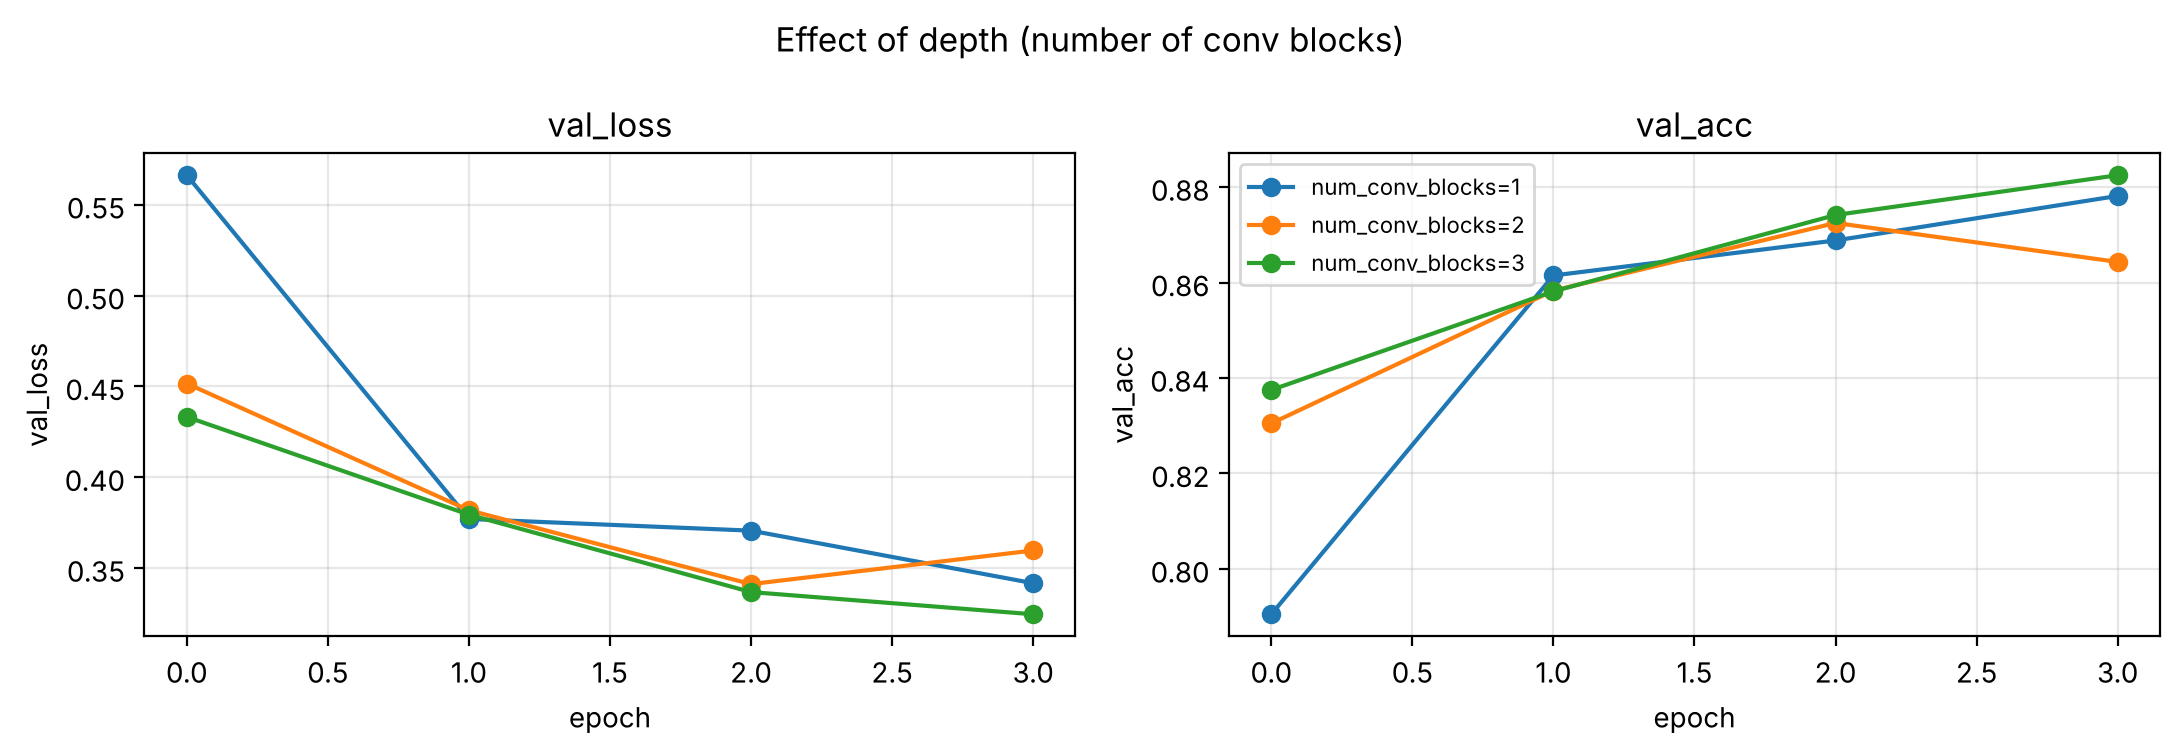

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
num_conv_blocks=1,0.878167,0.341710,0.325721,4,30.9
num_conv_blocks=2,0.872500,0.359716,0.316017,4,35.9
num_conv_blocks=3,0.882500,0.324604,0.302499,4,42.2


In [27]:
@dataclass
class HParams(HParams):          
    num_conv_blocks: int = 2     # depth: number of conv blocks (each one halves the image)
    in_channels: int = 1         # 1 = grayscale (Fashion-MNIST), 3 = colour (CIFAR-10)
    image_size: int = 28         # 28 for Fashion-MNIST, 32 for CIFAR-10


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act = ACTIVATIONS[hp.activation]

        def conv_block(in_ch, out_ch):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
            if hp.use_batchnorm:
                layers.append(nn.BatchNorm2d(out_ch))
            layers += [act(), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        # channels per block: conv1_channels, conv2_channels, then double each time
        channels = [hp.conv1_channels, hp.conv2_channels]
        while len(channels) < hp.num_conv_blocks:
            channels.append(channels[-1] * 2)
        channels = channels[: hp.num_conv_blocks]

        blocks, in_ch = [], hp.in_channels
        for out_ch in channels:
            blocks.append(conv_block(in_ch, out_ch))
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)

        # Work out the flattened size with one dummy image instead of hard-coding c2 * 7 * 7.
        with torch.no_grad():
            dummy = torch.zeros(1, hp.in_channels, hp.image_size, hp.image_size)
            flat_dim = self.features(dummy).numel()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),
            nn.Linear(flat_dim, hp.hidden_dim),
            act(),
            nn.Dropout(hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


FAST_DEPTH = HParams(train_subset=10_000, max_epochs=4, patience=100)

depth_values = [1, 2, 3]
print(pd.DataFrame({"trainable parameters": {
    f"num_conv_blocks={d}": count_parameters(SmallCNN(replace(FAST_DEPTH, num_conv_blocks=d)))
    for d in depth_values}}), "\n")

depth_results = run_configs("ex6_depth",
                            {f"num_conv_blocks={d}": {"num_conv_blocks": d} for d in depth_values},
                            base=FAST_DEPTH)
plot_runs(depth_results, "Effect of depth (number of conv blocks)")
summarize(depth_results)

`num_conv_blocks` now controls depth. Results: 1 block = 0.8782, 2 blocks = 0.8725, 3 blocks = 0.8825. The 2-block run matches section 6 exactly (0.8725), which confirms the new class behaves like the old one at the default. All three are within the 1.10-point seed spread, so depth makes no measurable difference on Fashion-MNIST in 4 epochs. Note that a deeper model here has **fewer** parameters (804,618 → 421,834 → 241,994), because each extra block halves the image and shrinks the big linear layer.

## Exercise 7 — Swap Fashion-MNIST for CIFAR-10

CIFAR-10 has 50,000 training images, **3 colour channels**, **32×32** pixels, 10 classes (airplane, car, bird, ...).

What has to change for the code to run at all:

- `datasets.FashionMNIST` → `datasets.CIFAR10`
- `in_channels`: 1 → 3 and `image_size`: 28 → 32 (so the first conv layer and the flattened size fit)
- normalisation mean/std: one value → three values (one per colour channel)
- augmentation crop: `RandomCrop(28, padding=2)` → `RandomCrop(32, padding=4)`

Then two runs on 10,000 CIFAR-10 images:

- **A. Fashion-MNIST settings**: the FAST config with only the changes above
- **B. Adjusted for CIFAR-10**: deeper and wider model, more epochs, augmentation, weight decay and a cosine schedule

/usr/local/lib/python3.13/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


A. Fashion-MNIST settings    best val_acc = 0.5814   params = 545,290   (48s)
B. adjusted for CIFAR-10     best val_acc = 0.7188   params = 1,423,114   (479s)

Fashion-MNIST, same FAST settings (section 6.1, lr=0.001): best val_acc = 0.8725


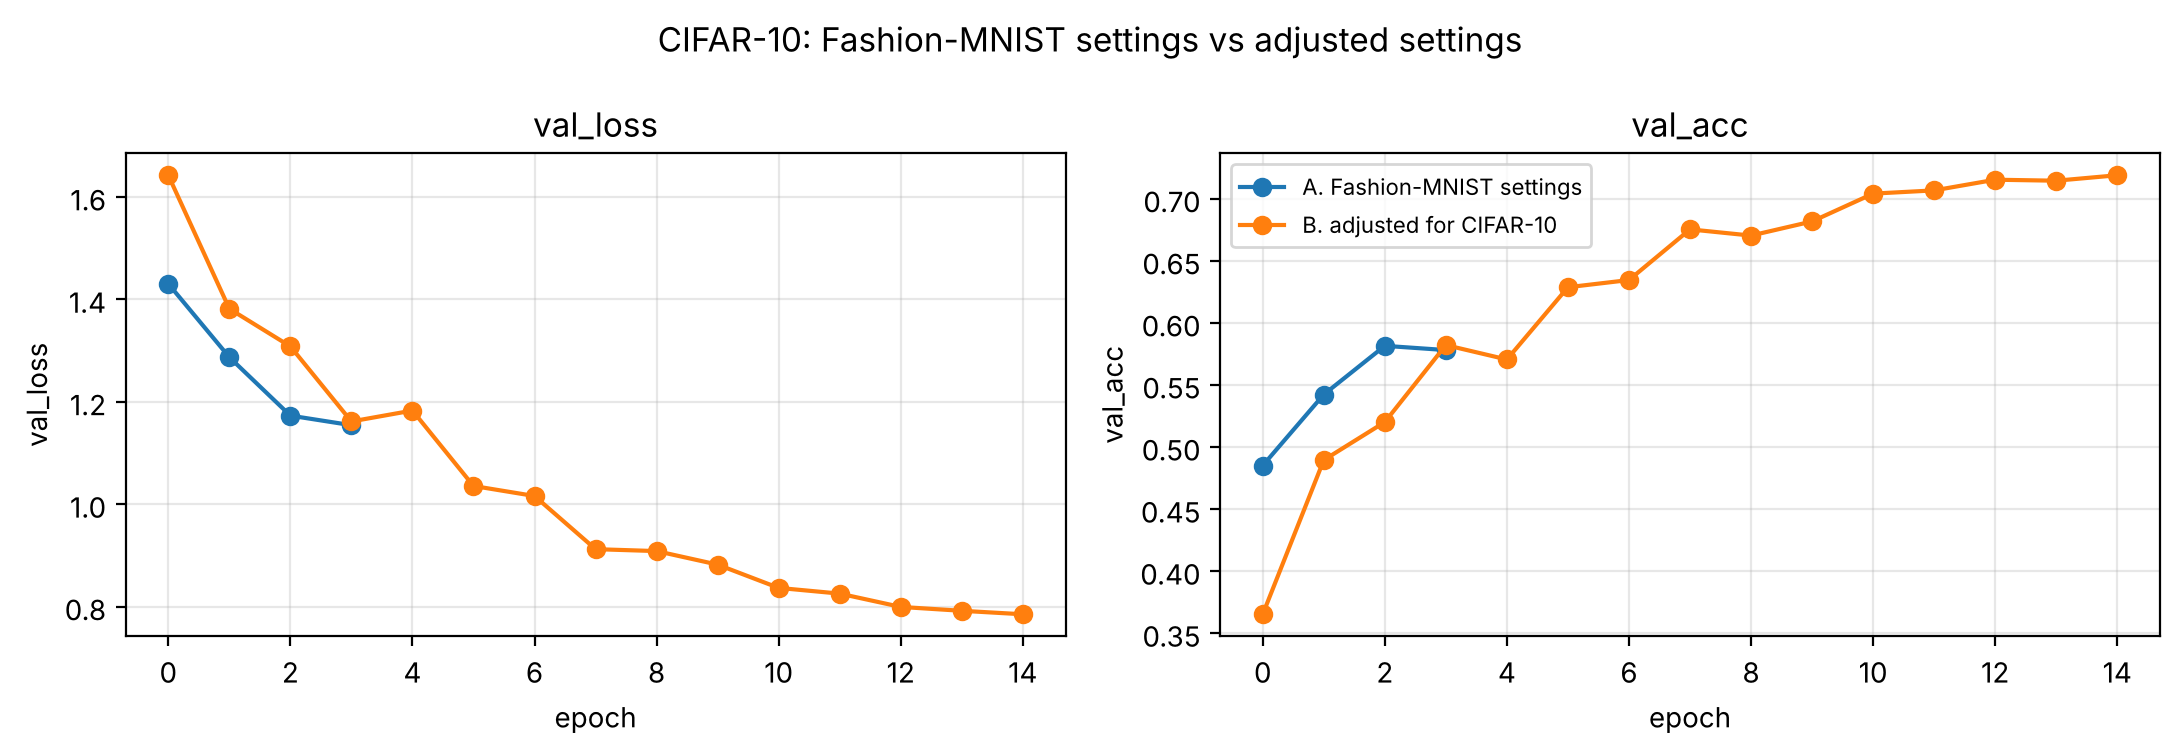

,best_val_acc,final_val_loss,final_train_loss,epochs,seconds
run,,,,,
A. Fashion-MNIST settings,0.5814,1.154160,1.161108,4,48.3
B. adjusted for CIFAR-10,0.7188,0.785005,0.864830,15,479.2


In [28]:
CIFAR_MEAN, CIFAR_STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)  # one value per colour channel


class CIFAR10DataModule(FashionMNISTDataModule):
    """Same logic as the Fashion-MNIST data module; only the dataset and transforms differ."""

    def __init__(self, hp: HParams):
        L.LightningDataModule.__init__(self)
        self.hp = hp
        normalize = transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
        self.eval_transform = transforms.Compose([transforms.ToTensor(), normalize])
        augmentations = []
        if hp.augment:
            augmentations = [transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()]
        self.train_transform = transforms.Compose([*augmentations, transforms.ToTensor(), normalize])

    def prepare_data(self):
        datasets.CIFAR10(self.hp.data_dir, train=True, download=True)
        datasets.CIFAR10(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        train_view = datasets.CIFAR10(self.hp.data_dir, train=True, transform=self.train_transform)
        eval_view = datasets.CIFAR10(self.hp.data_dir, train=True, transform=self.eval_transform)
        n_total = len(train_view)
        n_val = int(n_total * self.hp.val_fraction)
        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(n_total, generator=generator).tolist()
        val_idx, train_idx = indices[:n_val], indices[n_val:]
        if self.hp.train_subset is not None:
            train_idx = train_idx[: self.hp.train_subset]
        self.train_ds = Subset(train_view, train_idx)
        self.val_ds = Subset(eval_view, val_idx)
        self.test_ds = datasets.CIFAR10(self.hp.data_dir, train=False, transform=self.eval_transform)


def fit_cifar(hp: HParams, run_name: str):
    """Same as fit(), but with the CIFAR-10 data module."""
    for name in (_LIGHTNING_LOGGER, "lightning.fabric", "lightning_fabric"):
        logging.getLogger(name).setLevel(logging.ERROR)
    L.seed_everything(hp.seed, workers=True)
    datamodule = CIFAR10DataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger("logs", name=run_name)
    trainer = L.Trainer(max_epochs=hp.max_epochs, accelerator="auto", devices=1, logger=logger,
                        callbacks=[EarlyStopping(monitor="val_loss", mode="min", patience=hp.patience)],
                        enable_checkpointing=False, enable_progress_bar=False,
                        enable_model_summary=False, log_every_n_steps=10)
    trainer.fit(model, datamodule=datamodule)
    return load_history(logger.log_dir)


# The minimum that MUST change: input channels and image size.
CIFAR_FAST = HParams(train_subset=10_000, max_epochs=4, patience=100, in_channels=3, image_size=32)

cifar_configs = {
    "A. Fashion-MNIST settings": {},
    "B. adjusted for CIFAR-10": dict(num_conv_blocks=3, conv1_channels=64, conv2_channels=128,
                                     hidden_dim=256, max_epochs=15, augment=True,
                                     optimizer="adamw", weight_decay=0.01, scheduler="cosine"),
}
cifar_results = {}
for i, (label, overrides) in enumerate(cifar_configs.items()):
    hp_i = replace(CIFAR_FAST, **overrides)
    start = time.perf_counter()
    history = fit_cifar(hp_i, run_name=f"ex7_cifar10/run_{i}")
    seconds = time.perf_counter() - start
    cifar_results[label] = {"hp": hp_i, "history": history, "seconds": seconds}
    print(f"{label:<28} best val_acc = {history['val_acc'].max():.4f}   "
          f"params = {count_parameters(SmallCNN(hp_i)):,}   ({seconds:.0f}s)")

print(f"\nFashion-MNIST, same FAST settings (section 6.1, lr=0.001): "
      f"best val_acc = {lr_results['lr=0.001']['history']['val_acc'].max():.4f}")
plot_runs(cifar_results, "CIFAR-10: Fashion-MNIST settings vs adjusted settings")
summarize(cifar_results)

Must change, or the code does not run correctly: `in_channels` 1 → 3, `image_size` 28 → 32 (this changes the flattened size before the linear layer), the normalisation mean/std (three values) and the augmentation crop size (32). With only those changes, the Fashion-MNIST settings reach just **0.5814** on CIFAR-10, compared with 0.8725 on Fashion-MNIST, and train and validation loss are both still high (1.16 and 1.15), which is underfitting.

Should change because CIFAR-10 is harder: capacity (`num_conv_blocks`, `conv1_channels`, `conv2_channels`, `hidden_dim`), `max_epochs`, and regularisation (`augment`, `weight_decay`), plus a scheduler. With 3 blocks, 64/128 channels, `hidden_dim=256`, 15 epochs, augmentation, AdamW with `weight_decay=0.01` and cosine, accuracy rose to **0.7188**. Several settings were changed together in run B, so this shows the combined effect, not which single change helped most.